[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AndresOrdonez369/deepLearningWeek1/blob/main/proyectos/NB01_viernes_tu_primera_neurona.ipynb)

# NB01 · Tu primera neurona
**Neural Networks: Deep Learning · UIDE · Semana 1 · Viernes** — Docente: Andrés Ordóñez-Bolaños

En este Colab vas a **ver por dentro una neurona**: descubrirás que tu nota final del curso ya es una neurona, la pondrás a decidir créditos, la verás equivocarse y aprender, y al final bajarás una "montaña" con descenso de gradiente.

### ¿Por qué deep learning?
Imagina que tienes que escribir **a mano** las reglas para reconocer un gato en una foto, entender una frase o decidir si un socio pagará su crédito. Las reglas se vuelven miles, se contradicen y nunca alcanzan. **Las reglas no escalan.** La idea que cambió el mundo es otra: **mostrarle ejemplos a la máquina y dejar que ella encuentre la regla**. Así funcionan hoy el reconocimiento de voz del celular, los traductores, los filtros de spam o los asistentes como ChatGPT o Claude. La pieza más pequeña de todo eso es la que vas a ver hoy: **una neurona**.

### Seis palabras que vamos a usar todo el curso
| Palabra | Qué significa | Ejemplo de hoy |
|---|---|---|
| **dato** | un número que describe algo | el ingreso de un socio |
| **característica** | cada tipo de dato que miramos (una columna) | ingreso, antigüedad, atrasos |
| **ejemplo** | un caso completo (una fila) | el socio A con sus tres datos |
| **etiqueta** | la respuesta correcta de un ejemplo | pagó (+1) o no pagó (−1) |
| **modelo** | la fórmula con pesos que hace la predicción | la neurona |
| **predicción** | lo que el modelo responde | "aprueba" con 94 % |

### Cómo usar este Colab (2 minutos)
**Todo el código ya está escrito: tú lees, predices, ejecutas y comparas.** No tienes que programar nada para avanzar.

1. **Archivo → Guardar una copia en Drive.** Así tus cambios quedan guardados en tu cuenta.
2. Ejecuta la celda **Configuración** (la primera de código). Después avanza en orden: clic en la celda y `Shift + Enter`.
3. Cada sección sigue el mismo orden:
   **Qué vas a hacer → la necesidad → ejemplo → el nombre → la fórmula («Léelo así») → Qué hace este código → 🔮 Antes de ejecutar: ¿qué crees que saldrá? → ejecuta → Qué deberías ver → 💭 Para pensar.**
4. En **🔮 Antes de ejecutar** detente cinco segundos y apuesta un resultado. Acertar no importa; **comparar** sí.
5. En **💭 Para pensar** responde en tu cabeza (o con tu pareja) y después abre **Ver respuesta**.
6. Las celdas **🧪 Experimenta** son opcionales: cambia **un solo** valor marcado (por ejemplo `exigencia = 70   # try 80`) y vuelve a ejecutar.
7. **No tiene nota.** Equivocarse aquí es parte del plan.

> **🛟 Si algo falla**
> - `NameError: name 'x' is not defined` → te saltaste una celda de arriba. Usa **Entorno de ejecución → Ejecutar anteriores** (o **Ejecutar todo**).
> - Un error que menciona `shape` (forma) → los vectores no tienen el mismo largo; vuelve a ejecutar la celda original sin cambios.
> - Aparece `nan` o números gigantes → en un experimento pusiste un paso η demasiado grande (sección 8): vuelve al valor original.
> - Si cambiaste algo y ya no sabes qué: **Entorno de ejecución → Reiniciar y ejecutar todo**.

### Mapa del Colab
| Parte | Qué aprendes | Lámina |
|---|---|---|
| 0 | Python exprés: variables, listas, funciones, NumPy y gráficas (15 min, **si ya sabes Python, sáltala**) | — |
| 1 | Tu nota final es una neurona · el comité de crédito | 14–17 |
| 2 | La activación: de puntaje a decisión | 19–20 |
| 3 | El perceptrón corrige un error | 24–25 |
| 4 | Entrenar un perceptrón completo | 26 |
| 5 | El límite: XOR, la luz de la escalera | 27 |
| 6 | Error y pérdida: qué tan mal vamos | 31–33 |
| 7 | Derivada y descenso de gradiente: bajar el Cotopaxi | 34–36 |
| 8 | El tamaño del paso η | 37 |
| 🏁 | Resumen · **Para comprobar que entendiste** · Experimento 1 (opcional): tu propio comité de crédito | 40 |

En clase: secciones **1 a 5** en la práctica 1 (lámina 29) y **6 a 8** en la práctica 2 (lámina 40).

In [1]:
# @title Configuración · ejecuta esta celda primero (no necesitas abrirla)
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(2026)  # fixed seed -> everyone gets the same results
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

# The same colors as the slides: amber = yes / +1, azure = no / -1, mint = learned, coral = error
AMBAR, AZUL, MENTA, CORAL, TINTA = "#E39A12", "#2B8FD6", "#12A37F", "#E0533D", "#1F2A3A"

# Six students (S1, S2, S3, Final), used in "Para comprobar que entendiste"
GRUPO6 = np.array([[85, 90, 80, 75], [70, 60, 65, 80], [55, 75, 70, 90],
                   [90, 95, 85, 40], [65, 60, 55, 70], [72, 68, 74, 66]])

# Experiment 1 data: six members (scaled income, scaled previous delays); +1 = paid, -1 = did not pay
SOCIOS = np.array([[0.9, -0.8], [0.4, -0.2], [0.8, 0.3], [-0.5, 0.6], [0.1, 0.5], [-0.3, -0.1]])
PAGO = np.array([1, 1, 1, -1, -1, -1])
NOMBRES = ["Ana", "Byron", "Carla", "Diego", "Elena", "Fabián"]

def dibujar_comite(w, b):
    # Draws the six members and the line z = 0 of the neuron with weights w and bias b
    w = np.asarray(w, float)
    plt.figure(figsize=(5.5, 5))
    for (x1, x2), y, n in zip(SOCIOS, PAGO, NOMBRES):
        plt.scatter(x1, x2, s=170, c=AMBAR if y == 1 else AZUL, edgecolor=TINTA, zorder=3)
        plt.annotate(n, (x1, x2), textcoords="offset points", xytext=(9, 7))
    xs = np.linspace(-1, 1, 50)
    if abs(w[1]) > 1e-9:
        plt.plot(xs, -(w[0] * xs + b) / w[1], color=TINTA, lw=2.5, label="frontera del comité (z = 0)")
    plt.xlim(-1, 1); plt.ylim(-1, 1); plt.xlabel("ingreso (escalado)"); plt.ylabel("atrasos previos (escalado)")
    plt.title("Ámbar = pagó · Azul = no pagó"); plt.legend(loc="lower left"); plt.show()

print("Listo. NumPy", np.__version__)

Listo. NumPy 2.5.3


---
## 0 · Python exprés (15 min · si ya sabes Python, sáltala o hazla antes de clase)
**Qué vas a hacer:** repasar lo mínimo de Python que usa este curso con un ejemplo que conoces bien: **tu nota final**.

Según el sílabo, tu nota del curso se calcula así (cada nota sobre 100):

$$\text{Nota final} = 0.2667\cdot S_1 + 0.2667\cdot S_2 + 0.2667\cdot S_3 + 0.20\cdot \text{Final}$$

**Léelo así:** cada semana ($S_1, S_2, S_3$) pesa 26.67 % y el entrega final pesa 20 %; multiplicas cada nota por su peso y sumas todo. Guarda esta cuenta: en la sección 1 descubrirás que **es una neurona**.

### 0.1 · Variables y `print`
**Qué hace este código:**
- `nombre = "Ana"` crea una **variable**: un nombre que guarda un valor (aquí, un texto).
- `s1 = 80` guarda un número. El texto después de `#` es un **comentario**: Python lo ignora, es para ti.
- `print(...)` muestra cosas en pantalla. Con una **f-string** (`f"..."`) metes variables dentro del texto entre llaves `{}`; `{x:.1f}` significa "con un decimal".

In [2]:
# A variable is a name that stores a value
nombre = "Ana"
s1 = 80        # week 1 (out of 100)
s2 = 70        # week 2
s3 = 90        # week 3
final = 60     # final project

print("Estudiante:", nombre)
print(f"Notas de {nombre}: S1 = {s1}, S2 = {s2}, S3 = {s3}, Final = {final}")

promedio_simple = (s1 + s2 + s3 + final) / 4
print(f"Promedio simple (todas pesan igual): {promedio_simple:.1f}")   # :.1f -> one decimal

Estudiante: Ana
Notas de Ana: S1 = 80, S2 = 70, S3 = 90, Final = 60
Promedio simple (todas pesan igual): 75.0


**Qué deberías ver:** `Promedio simple (todas pesan igual): 75.0`. Pero en el curso las notas **no** pesan igual: para eso necesitamos pesos.

### 0.2 · Listas y el ciclo `for`
**Qué hace este código:**
- `[80, 70, 90, 60]` es una **lista**: varios valores en orden.
- `0.8 / 3` = 0.2667: las tres semanas se reparten el 80 %.
- `for parte, n, p in zip(partes, notas, pesos):` recorre las tres listas **a la vez**, una posición por vuelta: primera vuelta S1, 80, 0.2667; segunda vuelta S2, 70, 0.2667…
- Dentro del ciclo (las líneas con sangría) se calcula el aporte de cada nota y se va sumando en `nota`.

🔮 **Antes de ejecutar:** el promedio simple dio 75. Con estos pesos, ¿la nota de Ana sube o baja? (Pista: su nota más baja, 60, es la del proyecto, que pesa menos.)

In [3]:
notas  = [80, 70, 90, 60]                       # a list: Ana's four grades, in order
pesos  = [0.8 / 3, 0.8 / 3, 0.8 / 3, 0.20]      # syllabus weights: 26.67 % each week, 20 % the final project
partes = ["S1", "S2", "S3", "Final"]

print("Los pesos suman:", round(sum(pesos), 6))   # they must add up to 1 (100 %)

nota = 0
for parte, n, p in zip(partes, notas, pesos):    # walk the three lists together
    aporte = n * p                               # what this grade contributes
    nota = nota + aporte                         # running total
    print(f"{parte:5s}: {n:3d} × {p:.4f} = {aporte:5.2f}")
print(f"Nota final ponderada de Ana: {nota:.1f}")

Los pesos suman: 1.0
S1   :  80 × 0.2667 = 21.33
S2   :  70 × 0.2667 = 18.67
S3   :  90 × 0.2667 = 24.00
Final:  60 × 0.2000 = 12.00
Nota final ponderada de Ana: 76.0


**Qué deberías ver:** los pesos suman 1.0; cada semana aporta 21.33, 18.67 y 24.00; el proyecto 12.00; **nota final = 76.0**. Sube respecto a 75 porque el 60 pesa solo 20 %.

### 0.3 · Funciones
**Qué hace este código:**
- `def nota_final(notas, pesos):` crea una **función**: una cuenta empaquetada con nombre, para reutilizarla. `notas` y `pesos` son sus **parámetros** (lo que recibe).
- `return total` es lo que **devuelve**.
- Después la usamos dos veces: con Ana y con Beto (S1 = 60, S2 = 55, S3 = 65, Final = 70). La misma cuenta, otros datos.

🔮 **Antes de ejecutar:** Beto tiene notas más bajas en las semanas pero mejor proyecto. ¿Llegará a 70?

In [4]:
def nota_final(notas, pesos):
    # Weighted grade: each grade times its weight, all added up.
    total = 0
    for n, p in zip(notas, pesos):
        total = total + n * p
    return total

print(f"Ana:  {nota_final([80, 70, 90, 60], pesos):.1f}")
nota_beto = nota_final([60, 55, 65, 70], pesos)    # same function, Beto's grades
print(f"Beto: {nota_beto:.1f}")

Ana:  76.0
Beto: 62.0


**Qué deberías ver:** Ana 76.0 y **Beto 62.0**: sus tres semanas aportan 48 puntos y el proyecto 14. No llega a 70.

### 0.4 · NumPy: cuentas con vectores y tablas
**NumPy** es la librería de Python para trabajar con números en bloque (piensa en una hoja de cálculo muy rápida). Su pieza clave es el **array**.

**Qué hace este código:**
- `np.array([...])` convierte una lista en un **vector** de NumPy.
- `x * w` multiplica **elemento por elemento**, sin escribir un `for`.
- `x @ w` es el **producto punto**: multiplica parejas y suma. Es exactamente "cada nota por su peso, todo sumado".
- `.shape` dice la forma: `(4,)` es un vector de 4 números.

In [5]:
import numpy as np                    # already imported in Configuración; repeated so you see it

x = np.array([80, 70, 90, 60])        # Ana's grades as a vector
w = np.array(pesos)                   # the weights as a vector

print("x * w =", x * w)               # element by element
print("suma  =", (x * w).sum())
print("x @ w =", x @ w)               # dot product: the same 76.0 in one step
print("forma de x:", x.shape)

x * w = [21.33333333 18.66666667 24.         12.        ]
suma  = 76.0
x @ w = 76.0
forma de x: (4,)


**Qué deberías ver:** `x @ w = 76.0` (el mismo resultado del `for`, en una sola operación) y `forma de x: (4,)`.

Ahora tres estudiantes a la vez. **Qué hace este código:**
- `grupo` es una **tabla** (matriz): cada **fila** es una persona y cada **columna** una nota. Su forma es `(3, 4)`: 3 filas × 4 columnas.
- `grupo @ w` hace el producto punto **de cada fila** con los pesos: tres notas finales con una sola operación.

🔮 **Antes de ejecutar:** ya conoces dos de las tres notas. ¿Cuáles son?

In [6]:
grupo = np.array([[80, 70, 90, 60],    # Ana
                  [60, 55, 65, 70],    # Beto
                  [95, 85, 75, 90]])   # Carla
print("forma:", grupo.shape, "→ 3 estudiantes × 4 notas")

notas_grupo = grupo @ w                # one dot product per row
print("Notas finales:", notas_grupo)

forma: (3, 4) → 3 estudiantes × 4 notas
Notas finales: [76. 62. 86.]


**Qué deberías ver:** `forma: (3, 4)` y `Notas finales: [76. 62. 86.]` (Ana, Beto, Carla). Así calcula una red **una capa entera de neuronas**: una tabla de pesos `@` un vector de datos.

### 0.5 · Tu primera gráfica con matplotlib
**matplotlib** dibuja gráficas. **Qué hace este código:**
- `plt.subplots(1, 2)` crea una figura con **dos** gráficas lado a lado (`ax[0]` y `ax[1]`).
- `bar(...)` dibuja barras; `axhline(70)` traza una línea horizontal en 70.
- `colores = [MENTA if f >= 70 else CORAL ...]` pinta de verde a quien supera 70 y de coral a quien no.
- `plt.show()` muestra el dibujo.

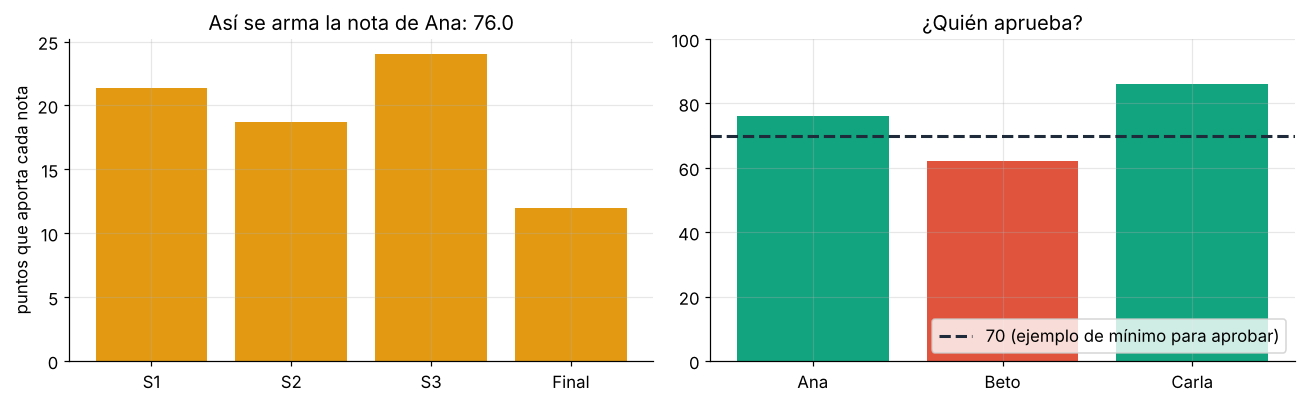

In [7]:
aportes = x * w

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))

# Left: how Ana's grade is built
ax[0].bar(partes, aportes, color=AMBAR)
ax[0].set_title(f"Así se arma la nota de Ana: {x @ w:.1f}")
ax[0].set_ylabel("puntos que aporta cada nota")

# Right: three students against an example passing bar of 70
finales = grupo @ w
colores = [MENTA if f >= 70 else CORAL for f in finales]
ax[1].bar(["Ana", "Beto", "Carla"], finales, color=colores)
ax[1].axhline(70, color=TINTA, ls="--", lw=2, label="70 (ejemplo de mínimo para aprobar)")
ax[1].set_ylim(0, 100); ax[1].set_title("¿Quién aprueba?"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Qué deberías ver:** a la izquierda, las cuatro barras que suman 76; a la derecha, Ana (76) y Carla (86) en verde por encima de la línea y Beto (62) en coral por debajo.

Con esto tienes todo el Python que necesitas hoy: **variables, listas, `for`, funciones, arrays de NumPy, `@` y gráficas.**

### 💭 Para pensar

**1.** ¿Qué diferencia hay entre `x * w` y `x @ w`?

<details><summary>Ver respuesta</summary>

`x * w` devuelve **un vector** con cada producto por separado (los aportes). `x @ w` multiplica y además **suma**: devuelve un solo número (la nota).
</details>

**2.** Si `grupo` tuviera 40 estudiantes, ¿qué forma tendría y cuántos números devolvería `grupo @ w`?

<details><summary>Ver respuesta</summary>

Forma `(40, 4)`; `grupo @ w` devolvería **40** notas, una por fila, con la misma línea de código.
</details>

---
## 1 · La neurona: tu nota final ya es una neurona
📽 Láminas 14–17

**Qué vas a hacer:** ver que una neurona hace exactamente la cuenta de tu nota final, y después usarla para decidir un crédito.

**La necesidad:** queremos una regla que tome varios datos y responda **sí o no**: ¿aprueba el curso?, ¿le damos el crédito? Lo más simple que se nos ocurre es: "a cada dato le doy una importancia, sumo todo y comparo con una exigencia". Eso es justo lo que hace el sílabo con tu nota.

**El nombre:** esa regla se llama **neurona artificial**. Recibe datos, multiplica cada uno por su **peso**, suma todo, agrega un **sesgo** y decide.

$$z = w_1x_1 + w_2x_2 + w_3x_3 + w_4x_4 + b \qquad\text{o, en corto,}\qquad z = \mathbf{w}\cdot\mathbf{x} + b$$

**Léelo así:** "z es igual a cada dato por su peso, todo sumado, más el sesgo".
- $x$ son los **datos** que entran (aquí, tus cuatro notas);
- $w$ son los **pesos**: cuánto importa cada dato **para esta cuenta** (26.67 %, 26.67 %, 26.67 %, 20 %);
- $b$ es el **sesgo**: un número que se suma siempre, haya lo que haya en los datos;
- $z$ es el **puntaje**: positivo → aprueba, negativo → no aprueba. Esa última decisión la toma la **activación** (sección 2).

**El sesgo, como un marcador:** piensa en un marcador que **empieza en −70** antes de mirar tus notas. Cada nota suma puntos y, si al final el marcador queda en cero o más, apruebas. Si se exigiera 80 en vez de 70, el marcador empezaría en −80. Por eso decimos que **el sesgo es la exigencia con el signo cambiado** (70 es solo un ejemplo de mínimo).

> Dos aclaraciones de palabras: en inglés el sesgo se llama *bias*, pero aquí **no significa prejuicio**; es solo el número que se suma al final. Y un peso alto no quiere decir que algo sea "más importante" en sentido moral: solo dice **cuánto mueve el puntaje** ese dato.

| Neurona | Tu nota del curso |
|---|---|
| datos $x$ | S1, S2, S3, Final |
| pesos $w$ | 0.2667, 0.2667, 0.2667, 0.20 |
| sesgo $b$ | −70 (ejemplo de mínimo para aprobar) |
| puntaje $z$ | nota − 70 |
| activación (escalón) | $z \ge 0$ → aprueba |

### Ejemplo: Ana como neurona
**Qué hace este código:**
- `x_ana` son los datos, `w_nota` los pesos y `b_nota = -exigencia` el sesgo.
- `w_nota @ x_ana + b_nota` es la fórmula de arriba, tal cual.
- `"aprueba" if z_ana >= 0 else "no aprueba"` es la decisión: si $z \ge 0$, aprueba.

🔮 **Antes de ejecutar:** la nota ponderada de Ana es 76 (sección 0). ¿Cuánto vale $z$?

In [8]:
exigencia = 70                                    # example passing bar   (🧪 try 80)

x_ana  = np.array([80, 70, 90, 60])               # inputs: S1, S2, S3, Final
w_nota = np.array([0.8 / 3, 0.8 / 3, 0.8 / 3, 0.2])   # weights: the syllabus percentages
b_nota = -exigencia                               # bias: the passing bar, sign flipped

z_ana = w_nota @ x_ana + b_nota                   # the neuron's score
decision = "aprueba" if z_ana >= 0 else "no aprueba"   # step activation

print(f"Nota ponderada  w·x = {w_nota @ x_ana:.1f}")
print(f"Puntaje z = {w_nota @ x_ana:.1f} + ({b_nota}) = {z_ana:+.1f}  →  {decision}")

Nota ponderada  w·x = 76.0
Puntaje z = 76.0 + (-70) = +6.0  →  aprueba


**Qué hace este código:** dibuja la misma suma como escalones: cada nota sube (ámbar), el sesgo baja (azul) y la barra final es lo que queda, $z$.

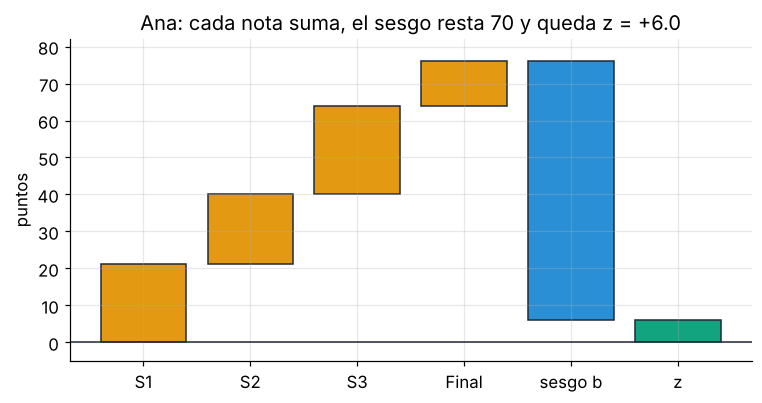

In [9]:
# Picture of the same sum: each grade pushes up, the bias pulls down, z is what is left
parts  = list(w_nota * x_ana) + [b_nota]
labels = ["S1", "S2", "S3", "Final", "sesgo b"]
start  = np.concatenate([[0], np.cumsum(parts)[:-1]])
colors = [AMBAR] * 4 + [AZUL]

plt.figure(figsize=(8, 3.8))
plt.bar(labels, parts, bottom=start, color=colors, edgecolor=TINTA)
plt.bar(["z"], [z_ana], color=MENTA if z_ana >= 0 else CORAL, edgecolor=TINTA)
plt.axhline(0, color=TINTA, lw=1)
plt.ylim(min(0, z_ana) - 5, 82)
plt.title(f"Ana: cada nota suma, el sesgo resta {exigencia} y queda z = {z_ana:+.1f}")
plt.ylabel("puntos"); plt.show()

**Qué deberías ver:** $w\cdot x = 76.0$ y **z = +6.0 → aprueba**. En la gráfica, las barras ámbar suben hasta 76, la azul baja 70 y la verde es lo que queda: 6. (Beto: 62 − 70 = −8 → no aprueba.)

🧪 **Experimenta:** en la primera línea cambia `exigencia = 70` por `80` y ejecuta las dos celdas otra vez. Verás **z = 76 − 80 = −4 → no aprueba**: los pesos no cambiaron, solo el sesgo. Después regrésalo a 70.

### ¿Cuánto necesita Ana en el entrega final?
Las semanas de Ana aportan 64 puntos. ¿Qué nota $F$ en el entrega final la deja **justo** en el límite, es decir, con $z = 0$?

En el límite: $\;64 + 0.2\cdot F - 70 = 0 \;\Rightarrow\; F = (70 - 64) / 0.2$.

**Qué hace este código:** hace esa cuenta y después **comprueba** el resultado metiéndolo en la neurona: si está bien, $z$ debe dar exactamente 0.

🔮 **Antes de ejecutar:** ¿necesita más o menos de 50?

In [10]:
final_necesario = (70 - 64) / 0.2                 # z = 0  ->  64 + 0.2 F - 70 = 0
print("Nota necesaria en el entrega final:", final_necesario)

# check: put that grade into the neuron, z should be exactly 0
z_limite = w_nota @ np.array([80, 70, 90, final_necesario]) - 70
print(f"comprobación: z = {z_limite:.2f}")

Nota necesaria en el entrega final: 30.0
comprobación: z = 0.00


**Qué deberías ver:** `Nota necesaria en el entrega final: 30.0` y `comprobación: z = 0.00`. Con 30 Ana queda **justo en la frontera** entre aprobar y no aprobar.

### 💭 Para pensar

**1.** Si la exigencia sube de 70 a 80, ¿qué cambia en la neurona: los pesos o el sesgo?

<details><summary>Ver respuesta</summary>

Solo el **sesgo**: pasa de −70 a −80. Los pesos (los porcentajes del sílabo) siguen iguales.
</details>

**2.** ¿Qué significa que $z$ sea exactamente 0?

<details><summary>Ver respuesta</summary>

Que el ejemplo está **justo en la frontera**: un punto más y aprueba, un punto menos y no.
</details>

### De la nota al crédito: los pesos pueden ser negativos
**La necesidad:** en tu nota, los pesos los pone el sílabo y todos suman. Pero en un crédito hay datos que **ayudan** (el ingreso) y datos que **perjudican** (los atrasos). Necesitamos pesos que también puedan **restar**.

**El nombre:** un **peso negativo**. Y en una red de verdad **los pesos no los pone nadie: la red los aprende de ejemplos** (secciones 3 y 4).

**Datos escalados.** Antes de entrar a la neurona, cada dato se pasa a una escala común donde **0 es el promedio de los socios**, **+1** es "bastante por encima del promedio" y **−1** "bastante por debajo". Por ejemplo, si el ingreso promedio es 1 000 USD y la variación típica (desviación estándar) es 200 USD, entonces 1 200 USD se vuelve **+1** y 800 USD se vuelve **−1**. Así ningún dato domina solo por estar en una unidad más grande.

**Ejemplo: el comité de crédito.** Una cooperativa evalúa al **socio A** con tres datos escalados:

| Dato | Valor $x$ | Peso $w$ | Qué significa el peso |
|---|---|---|---|
| Ingreso | 0.8 | 1.2 | suma a favor |
| Antigüedad como socio | 0.5 | 0.7 | suma a favor |
| Atrasos previos | −1.0 (menos atrasos que el promedio) | −2.0 | los atrasos **restan** |

El sesgo $b = -0.5$ es un comité algo exigente: el marcador empieza restando medio punto.

**Qué hace este código:**
- `contributions = w * x` calcula el aporte de cada dato por separado.
- `z = contributions.sum() + b` los suma y agrega el sesgo (es lo mismo que `w @ x + b`).
- El `for` imprime cada aporte con su signo; la gráfica de barras muestra en ámbar lo que suma y en azul lo que resta.

🔮 **Antes de ejecutar:** los atrasos tienen peso negativo. ¿Su aporte será positivo o negativo para el socio A?

Ingreso     aporta +0.96
Antigüedad  aporta +0.35
Atrasos     aporta +2.00
Sesgo       aporta -0.50
Puntaje total z = 2.81  →  aprueba


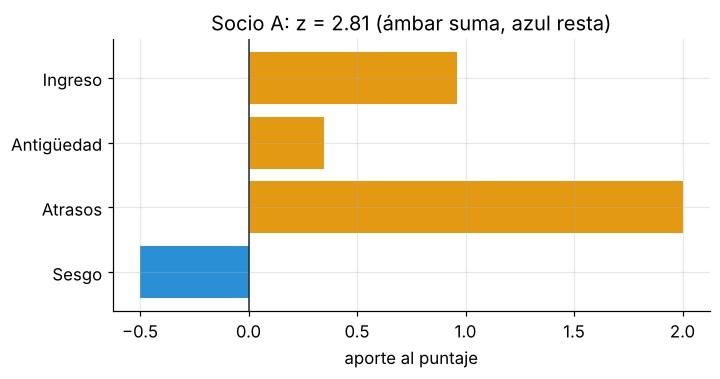

In [11]:
x = np.array([0.8, 0.5, -1.0])    # member A: income, seniority, previous delays (scaled)
w = np.array([1.2, 0.7, -2.0])    # weights: how much the committee trusts each signal
b = -0.5                          # bias: how demanding the committee is

contributions = w * x             # each input times its weight
z = contributions.sum() + b       # weighted sum + bias  (the same as w @ x + b)

for name, c in zip(["Ingreso", "Antigüedad", "Atrasos"], contributions):
    print(f"{name:11s} aporta {c:+.2f}")
print(f"Sesgo       aporta {b:+.2f}")
print(f"Puntaje total z = {z:.2f}  →  {'aprueba' if z >= 0 else 'rechaza'}")

plt.figure(figsize=(7, 3.2))
vals = list(contributions) + [b]
plt.barh(["Ingreso", "Antigüedad", "Atrasos", "Sesgo"], vals, color=[AMBAR if v > 0 else AZUL for v in vals])
plt.axvline(0, color=TINTA, lw=1); plt.gca().invert_yaxis()
plt.title(f"Socio A: z = {z:.2f} (ámbar suma, azul resta)"); plt.xlabel("aporte al puntaje"); plt.show()

**Qué deberías ver:** aportes +0.96, +0.35 y **+2.00**; sesgo −0.50; **z = 2.81 → aprueba**.
Fíjate en los atrasos: un peso negativo (−2.0) por un dato negativo (−1.0) da un aporte **positivo**: tener menos atrasos que el promedio ayuda mucho.

### La neurona como función: el socio B
**La necesidad:** no queremos reescribir la cuenta para cada socio. La empaquetamos en una **función** (sección 0.3) que sirva con cualquier vector.

**Qué hace este código:**
- `def neurona(x, w, b): return w @ x + b` es toda la neurona en una línea: producto punto más sesgo.
- `x_b` son los datos del **socio B**: ingreso 0.2 (casi el promedio), antigüedad −0.5 (poca), atrasos **1.5** (muchos más que el promedio).
- Usamos los **mismos** pesos `w` y sesgo `b` del comité.

🔮 **Antes de ejecutar:** con tantos atrasos y peso −2.0, ¿cuánto restarán los atrasos? ¿Aprobará?

In [12]:
def neurona(x, w, b):
    return w @ x + b     # weighted sum plus bias: the whole neuron

x_b = np.array([0.2, -0.5, 1.5])      # member B: income, seniority, previous delays (scaled)
z_b = neurona(x_b, w, b)              # same committee weights and bias
print("aportes del socio B:", w * x_b)
print(f"z del socio B: {z_b:.2f}  →  {'aprueba' if z_b >= 0 else 'rechaza'}")
print(f"comprobación con el socio A: {neurona(x, w, b):.2f}")

aportes del socio B: [ 0.24 -0.35 -3.  ]
z del socio B: -3.61  →  rechaza
comprobación con el socio A: 2.81


**Qué deberías ver:** aportes `[ 0.24 -0.35 -3.  ]`, **z = −3.61 → rechaza** y la comprobación con el socio A otra vez en **2.81**. Los atrasos solos restan 3 puntos.

### 💭 Para pensar

**1.** ¿Por qué el aporte de los atrasos fue **+2.00** para el socio A y **−3.00** para el socio B, si el peso es el mismo (−2.0)?

<details><summary>Ver respuesta</summary>

Porque cambia el **dato**: A tiene −1.0 (menos atrasos que el promedio) y −2.0 × −1.0 = +2.0; B tiene +1.5 (más atrasos) y −2.0 × 1.5 = −3.0.
</details>

**2.** ¿Qué significa un dato escalado de 0?

<details><summary>Ver respuesta</summary>

Que ese socio está **justo en el promedio** en ese dato; su aporte al puntaje es 0, sea cual sea el peso.
</details>

**3.** ¿Quién decidió aquí los pesos 1.2, 0.7 y −2.0?

<details><summary>Ver respuesta</summary>

Nosotros, a mano, para el ejemplo. En una red real **se aprenden de ejemplos** con etiquetas: eso empieza en la sección 3.
</details>

---
## 2 · La activación: de puntaje a decisión
📽 Láminas 19–21

**Qué vas a hacer:** convertir el puntaje $z$ en la salida de la neurona con tres funciones distintas y compararlas.

**La necesidad:** $z = 2.81$ o $z = -3.61$ todavía no es una respuesta. El comité necesita "sí/no" o, mejor aún, **qué tan seguro** está.

**El nombre:** una **función** es una regla que recibe un número y devuelve otro. La **función de activación** recibe $z$ y devuelve la salida de la neurona. El **umbral** es el valor de corte donde la decisión cambia de "no" a "sí".

- **Escalón** — un interruptor: todo o nada. $z \ge 0$ → 1 (aprueba); si no → 0. Su umbral es $z = 0$.
- **Sigmoide** — un regulador de luz: un valor suave entre 0 y 1 que se lee como **probabilidad estimada**.
- **ReLU** — una válvula: si $z$ es negativo no pasa nada (0); si es positivo pasa igual. Es la más usada dentro de las redes.

$$\sigma(z) = \frac{1}{1+e^{-z}} \qquad \text{ReLU}(z) = \max(0, z)$$

**Léelo así (sigmoide):** "uno dividido entre uno más $e$ a la menos $z$". Si $z$ es muy grande, $e^{-z}$ casi vale 0 y queda $1/1 = 1$; si $z$ es muy negativo, $e^{-z}$ es enorme y queda casi 0; si $z = 0$, queda $1/2$: la neurona duda.

### Ejemplo: el socio A ($z = 2.81$)
**Qué hace este código:**
- `lambda z: ...` es una forma corta de escribir una función de una línea.
- `np.where(z >= 0, 1.0, 0.0)` = "si z ≥ 0 devuelve 1, si no 0" (el escalón).
- `np.exp(-z)` es $e^{-z}$; `np.maximum(0, z)` es el máximo entre 0 y z.

🔮 **Antes de ejecutar:** para $z = 2.81$, ¿la sigmoide dará cerca de 0.5, de 0.9 o de 1.0 exacto?

In [13]:
step    = lambda z: np.where(z >= 0, 1.0, 0.0)   # switch
sigmoid = lambda z: 1 / (1 + np.exp(-z))         # dimmer: 0..1
relu    = lambda z: np.maximum(0, z)             # valve

print(f"Para z = {z:.2f}:  escalón = {step(z):.0f} | sigmoide = {sigmoid(z):.3f} | ReLU = {relu(z):.2f}")
print(f"Para z = 0:     sigmoide = {sigmoid(0):.3f}  (la neurona duda)")
print(f"Para z = -{z:.2f}: sigmoide = {sigmoid(-z):.3f}")

Para z = 2.81:  escalón = 1 | sigmoide = 0.943 | ReLU = 2.81
Para z = 0:     sigmoide = 0.500  (la neurona duda)
Para z = -2.81: sigmoide = 0.057


**Qué hace este código:** dibuja las tres activaciones entre $z = -6$ y $z = 6$ y marca con un punto negro dónde cae el socio A.

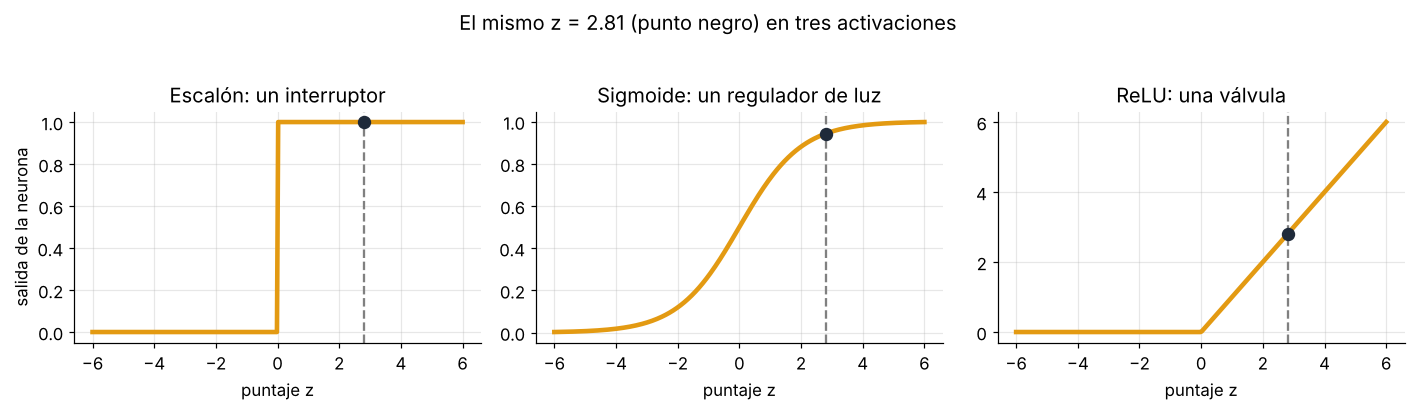

In [14]:
zz = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, f, name, sub in zip(ax, [step, sigmoid, relu], ["Escalón", "Sigmoide", "ReLU"],
                           ["un interruptor", "un regulador de luz", "una válvula"]):
    a.plot(zz, f(zz), lw=3, color=AMBAR)
    a.axvline(z, ls="--", color="gray"); a.scatter([z], [f(z)], s=60, color=TINTA, zorder=3)
    a.set_title(f"{name}: {sub}"); a.set_xlabel("puntaje z")
ax[0].set_ylabel("salida de la neurona")
plt.suptitle("El mismo z = 2.81 (punto negro) en tres activaciones", y=1.03); plt.tight_layout(); plt.show()

**Qué deberías ver:** escalón = 1 (aprueba), sigmoide ≈ **0.943**, ReLU = 2.81; con $z = 0$ la sigmoide da 0.5 y con $z = -2.81$, 0.057.

> **Cuidado con la palabra "probabilidad".** 0.943 es la **probabilidad estimada** por el modelo con estos pesos: "de cada 100 socios parecidos, esperaríamos que unos 94 paguen". **No es una garantía** sobre el socio A, y solo es tan buena como los datos y los pesos.

### Del puntaje a la decisión: el socio B
**Qué hace este código:**
- `p_b = sigmoid(z_b)` convierte el $z = -3.61$ del socio B en probabilidad.
- `umbral = 0.5` es el corte: si la probabilidad es al menos 0.5, aprueba.

🔮 **Antes de ejecutar:** $z_b = -3.61$ es bastante negativo. ¿La probabilidad estará cerca de 0, de 0.5 o de 1?

In [15]:
umbral = 0.5                                     # cut-off: approve if p >= umbral   (🧪 try 0.02)

p_b = sigmoid(z_b)                               # member B's estimated probability of paying
decision_b = "aprueba" if p_b >= umbral else "rechaza"
print(f"Probabilidad estimada de pago del socio B: {p_b:.3f}  ({p_b:.1%})  →  {decision_b}")

Probabilidad estimada de pago del socio B: 0.026  (2.6%)  →  rechaza


**Qué deberías ver:** `0.026 (2.6%) → rechaza`.

🧪 **Experimenta:** cambia `umbral = 0.5` por `0.02` y ejecuta. Ahora el socio B **aprueba**, aunque su probabilidad sigue siendo 2.6 %. El umbral no lo aprende la neurona: es una **decisión del negocio** (¿cuánto riesgo aceptamos?). Regrésalo a 0.5.

<details><summary>Para curiosos: ¿por qué hace falta la activación?</summary>

Sin activación, apilar capas no sirve: una suma de sumas sigue siendo una suma, y su frontera sigue siendo una línea recta. La activación "dobla" la línea; con muchos dobleces la red arma cualquier curva (lámina 21).
</details>

### 💭 Para pensar

**1.** ¿Qué devuelve la sigmoide cuando $z = 0$, y qué significa?

<details><summary>Ver respuesta</summary>

0.5: la neurona **duda**, está justo en la frontera.
</details>

**2.** Si la sigmoide dice 0.943 para el socio A, ¿es seguro que pagará?

<details><summary>Ver respuesta</summary>

No. Es una **probabilidad estimada** con estos pesos; de cada 100 socios parecidos esperaríamos que unos 94 paguen, pero el socio A puede ser de los 6 que no.
</details>

**3.** ¿Quién elige el umbral 0.5: la neurona o las personas?

<details><summary>Ver respuesta</summary>

Las personas (el negocio). La neurona da el puntaje y la probabilidad; dónde cortar depende de cuánto riesgo se quiere aceptar.
</details>

---
## 3 · El perceptrón corrige UN error
📽 Láminas 24–25

**Qué vas a hacer:** ver paso a paso la regla con la que aprende el perceptrón (Rosenblatt, 1958).

**La necesidad:** hasta ahora pusimos los pesos a mano. Queremos que la neurona **los ajuste sola** a partir de ejemplos con su etiqueta (pagó / no pagó).

**La idea:** como **sazonar un locro**: pruebas, notas que le falta sal y echas **una pizca**, no medio salero. El perceptrón se corrige **solo cuando se equivoca**, un poquito, en la dirección de la respuesta correcta.

**El nombre:** el **perceptrón** es una neurona con escalón que aprende con esta regla. Usa etiquetas $y = +1$ (debía aprobar / pagó) y $y = -1$ (debía rechazar / no pagó). Se usan +1 y −1, en vez de 1 y 0, porque así el signo de $y$ dice directamente si hay que **sumar** o **restar**:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta \cdot y \cdot \mathbf{x} \qquad\qquad b \leftarrow b + \eta \cdot y$$

**Léelo así:** "el peso nuevo es el peso viejo **más** η (el tamaño de la pizca) **por** $y$ (+1 o −1) **por** $x$ (el dato que clasificó mal)". Si debía aprobar, le *suma* el dato; si debía rechazar, se lo *resta*. Si acertó, no toca nada.

### Ejemplo 1: debía aprobar y rechazó ($y = +1$)
**Qué hace este código:**
- `y_i * z_before <= 0` detecta el error: si $y$ y $z$ tienen signos distintos (o $z = 0$), la neurona se equivocó.
- Si hay error, aplica la regla: `w + eta * y_i * x_i` y `b + eta * y_i`.
- Calcula $z$ otra vez con los pesos corregidos.

🔮 **Antes de ejecutar:** con $y = +1$ y $\mathbf{x} = (1, 1)$, ¿los pesos van a subir o a bajar?

In [16]:
w = np.array([0.2, -0.5]); b = 0.0; eta = 1.0     # current weights
x_i = np.array([1.0, 1.0]); y_i = +1              # a member who SHOULD be approved

z_before = w @ x_i + b
print(f"Antes:   z = {z_before:+.2f} -> predice {'aprobar' if z_before >= 0 else 'rechazar'} (correcto: aprobar)")
w_before, b_before = w.copy(), b

if y_i * z_before <= 0:          # mistake (signs disagree) -> correct the weights
    w = w + eta * y_i * x_i
    b = b + eta * y_i
print(f"Pesos corregidos: w = {w}, b = {b}")

z_after = w @ x_i + b
print(f"Después: z = {z_after:+.2f} -> predice {'aprobar' if z_after >= 0 else 'rechazar'}")

Antes:   z = -0.30 -> predice rechazar (correcto: aprobar)
Pesos corregidos: w = [1.2 0.5], b = 1.0
Después: z = +2.70 -> predice aprobar


**Qué hace este código:** dibuja la frontera ($z = 0$) antes (coral, punteada) y después (verde) de la corrección, con el socio en ámbar.

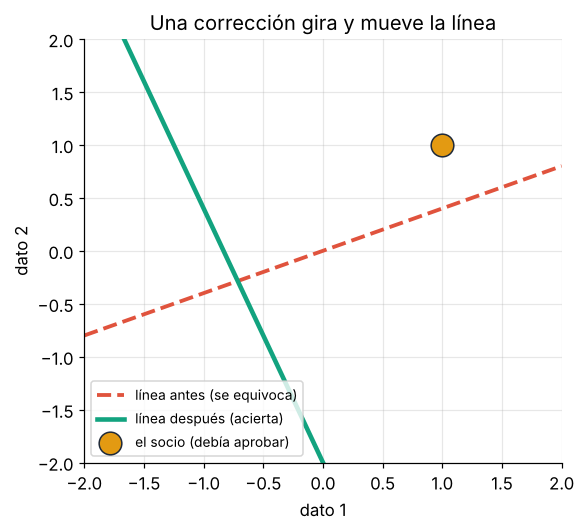

In [17]:
# The decision line z = 0 before and after the correction
xs = np.linspace(-2, 2, 50)
plt.figure(figsize=(5.6, 5))
plt.plot(xs, -(w_before[0] * xs + b_before) / w_before[1], color=CORAL, lw=2.5, ls="--", label="línea antes (se equivoca)")
plt.plot(xs, -(w[0] * xs + b) / w[1], color=MENTA, lw=3, label="línea después (acierta)")
plt.scatter(*x_i, s=220, color=AMBAR, edgecolor=TINTA, zorder=3, label="el socio (debía aprobar)")
plt.xlim(-2, 2); plt.ylim(-2, 2); plt.xlabel("dato 1"); plt.ylabel("dato 2")
plt.title("Una corrección gira y mueve la línea"); plt.legend(loc="lower left", fontsize=9); plt.show()

**Qué deberías ver:** antes z = **−0.30** (se equivoca y rechaza); después de corregir w = (1.2, 0.5), b = 1 y z = **+2.70** (ahora aprueba). En la gráfica la línea saltó para dejar al socio del lado de "aprobar".

### Ejemplo 2: el error al revés ($y = -1$)
Ahora el comité tiene `w = (1.2, 0.5)` y `b = 1`. Llega un socio `x = (1.0, 0.5)` que **no pagó** ($y = -1$), pero la neurona lo aprueba (z = 2.45).

**Qué hace este código:** aplica **una** corrección con η = 1. Como $y = -1$, la regla **resta** el dato: $\mathbf{w} - \mathbf{x}$ y $b - 1$. Después vuelve a calcular $z$ para ver si ya acierta.

🔮 **Antes de ejecutar:** ¿una sola corrección bastará para que lo rechace?

In [18]:
w = np.array([1.2, 0.5]); b = 1.0; eta = 1.0
x_i = np.array([1.0, 0.5]); y_i = -1              # a member who did NOT pay

print(f"Antes:   z = {w @ x_i + b:+.2f}  (aprueba: se equivoca)")
w_nuevo = w + eta * y_i * x_i                     # y = -1 -> subtract the input
b_nuevo = b + eta * y_i
z_nuevo = w_nuevo @ x_i + b_nuevo
todavia_se_equivoca = bool(y_i * z_nuevo <= 0)
print(f"Pesos nuevos: w = {w_nuevo}, b = {b_nuevo}")
print(f"Después: z = {z_nuevo:+.2f}  →  ¿todavía se equivoca? {todavia_se_equivoca}")

Antes:   z = +2.45  (aprueba: se equivoca)
Pesos nuevos: w = [0.2 0. ], b = 0.0
Después: z = +0.20  →  ¿todavía se equivoca? True


**Qué deberías ver:** w nuevo = (0.2, 0.0), b nuevo = 0, z = **+0.20** → **todavía se equivoca** (True). La corrección acercó la frontera (z bajó de 2.45 a 0.20), pero no bastó: por eso el perceptrón da **varias vueltas** por los datos.

### 💭 Para pensar

**1.** ¿Qué hace la regla cuando la neurona **acierta**?

<details><summary>Ver respuesta</summary>

Nada: los pesos no se tocan. El perceptrón solo aprende de sus errores.
</details>

**2.** ¿Por qué las etiquetas son +1 y −1 y no 1 y 0?

<details><summary>Ver respuesta</summary>

Porque el signo de $y$ decide la dirección de la corrección: +1 suma el dato y −1 lo resta. Con 0 la regla no corregiría nada.
</details>

**3.** En el ejemplo 2, una corrección no bastó. ¿Qué crees que pasará si ese socio vuelve a aparecer?

<details><summary>Ver respuesta</summary>

Se aplica otra corrección: $w$ baja otra vez y $z$ pasa a ser negativo, así que ya lo rechaza. Lo verás en la sección 4 con muchas vueltas.
</details>

---
## 4 · Entrenar un perceptrón completo
📽 Lámina 26

**Qué vas a hacer:** repetir la regla sobre muchos socios hasta que la neurona deje de equivocarse, y **ver moverse la línea**.

**La idea:** recorrer todos los ejemplos corrigiendo cada error. **El nombre:** cada vuelta completa por todos los datos se llama **época**. Si existe una línea que separa a los que pagan de los que no, el perceptrón la encuentra (teorema de Novikoff, 1962).

### Ejemplo: 120 socios ficticios
**Qué hace este código:**
- `np.random.uniform(-1, 1, size=(n, 2))` inventa 120 socios con dos datos escalados entre −1 y 1.
- Una regla "verdadera" (que el perceptrón **no** conoce) decide quién pagó; `keep` deja un pequeño hueco entre los dos grupos para que se puedan separar con una línea.
- `y` queda con +1 (pagó) o −1 (no pagó): son las **etiquetas**.

In [19]:
np.random.seed(2026)                               # same data for everyone
n = 120
X = np.random.uniform(-1, 1, size=(n, 2))          # 120 members, 2 scaled features
margin = X @ np.array([1.0, 1.6]) - 0.1            # the hidden "true" rule
keep = np.abs(margin) > 0.1                        # leave a small gap between the classes
X, y = X[keep], np.where(margin[keep] > 0, 1, -1)  # +1 = paid, -1 = did not pay
print("Socios:", X.shape[0], "| pagaron:", (y == 1).sum(), "| no pagaron:", (y == -1).sum())

Socios: 113 | pagaron: 54 | no pagaron: 59


**La función de entrenamiento. Qué hace este código, línea por línea:**
- `w, b = np.zeros(...), 0.0` — empieza con todos los pesos en 0 (no sabe nada).
- `for epoch in range(epochs):` — el ciclo de **épocas** (máximo 50 vueltas).
- `for xi, yi in zip(X, y):` — dentro de cada época, recorre los socios uno por uno.
- `if yi * (w @ xi + b) <= 0:` — ¿se equivocó con este socio? Entonces aplica la regla de la sección 3 y cuenta un error.
- `trace.append(...)` — guarda los pesos después de cada corrección, solo para poder dibujar cómo se movió la línea.
- `if mistakes == 0: break` — si dio una vuelta entera sin errores, terminó.

🔮 **Antes de ejecutar:** ¿cuántas épocas crees que necesitará: 1, 2 o 50?

In [20]:
def train_perceptron(X, y, eta=1.0, epochs=50, trace=None):
    w, b, history = np.zeros(X.shape[1]), 0.0, []
    for epoch in range(epochs):
        mistakes = 0
        for xi, yi in zip(X, y):
            if yi * (w @ xi + b) <= 0:             # wrong (or undecided) -> correct
                w, b = w + eta * yi * xi, b + eta * yi
                mistakes += 1
                if trace is not None:
                    trace.append((w.copy(), b))    # remember the line after this correction
        history.append(mistakes)
        if mistakes == 0:                          # a full pass without errors: done
            break
    return w, b, history

lineas = []
w_p, b_p, hist = train_perceptron(X, y, trace=lineas)
print("Errores por época:", hist, "| correcciones:", len(lineas))

Errores por época: [8, 0] | correcciones: 8


**Qué hace este código:** toma cuatro "fotos" del aprendizaje (después de la corrección 1, 3, 5 y la última). El fondo ámbar es lo que la neurona aprueba y el azul lo que rechaza; los círculos coral son los socios mal clasificados en ese momento.

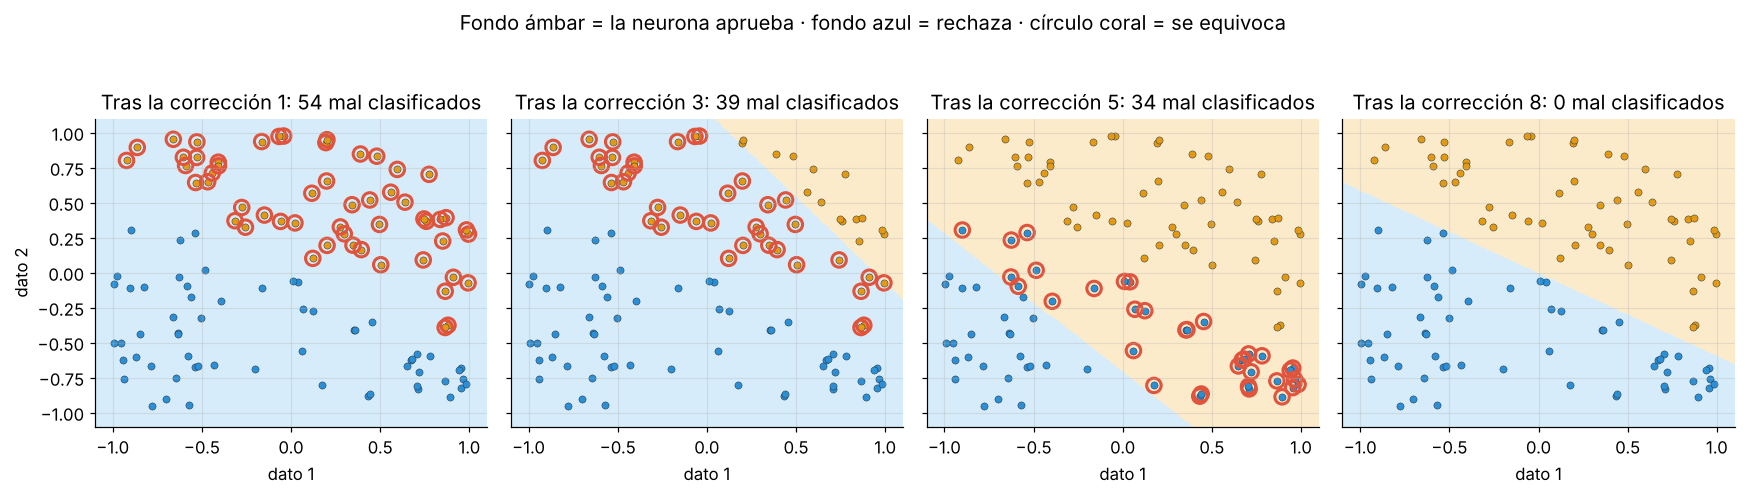

In [21]:
# Four snapshots of the learning: shaded = what the neuron approves (amber) or rejects (azure)
g1, g2 = np.meshgrid(np.linspace(-1.1, 1.1, 200), np.linspace(-1.1, 1.1, 200))
picks = [0, 2, 4, len(lineas) - 1]                      # after correction 1, 3, 5 and the last one
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3), sharey=True)
for a, k in zip(ax, picks):
    wk, bk = lineas[k]
    zone = (wk[0] * g1 + wk[1] * g2 + bk) >= 0
    a.contourf(g1, g2, zone, levels=[-.5, .5, 1.5], colors=["#D6ECFA", "#FCEBCB"])
    wrong = np.where(X @ wk + bk >= 0, 1, -1) != y
    a.scatter(*X[y == 1].T, c=AMBAR, s=22, edgecolor=TINTA, lw=.3)
    a.scatter(*X[y == -1].T, c=AZUL, s=22, edgecolor=TINTA, lw=.3)
    a.scatter(*X[wrong].T, s=90, facecolors="none", edgecolors=CORAL, linewidths=2)
    a.set_title(f"Tras la corrección {k + 1}: {wrong.sum()} mal clasificados")
    a.set_xlim(-1.1, 1.1); a.set_ylim(-1.1, 1.1); a.set_xlabel("dato 1")
ax[0].set_ylabel("dato 2")
plt.suptitle("Fondo ámbar = la neurona aprueba · fondo azul = rechaza · círculo coral = se equivoca", y=1.04)
plt.tight_layout(); plt.show()

**Qué deberías ver:** errores por época **[8, 0]**: en la primera vuelta se equivoca 8 veces y se corrige cada vez; en la segunda vuelta ya no falla con nadie. En las cuatro fotos, la frontera entre el fondo ámbar y el azul gira y se mueve hasta que ya no queda ningún círculo coral.

### Ejemplo: la compuerta AND
AND es "los dos a la vez": vale $+1$ solo si ambos interruptores están en 1.

| $x_1$ | $x_2$ | AND |
|---|---|---|
| 0 | 0 | −1 |
| 0 | 1 | −1 |
| 1 | 0 | −1 |
| 1 | 1 | +1 |

**Qué hace este código:** escribe la tabla en `X_and` (los 4 casos) y `y_and` (sus etiquetas), entrena con la misma función `train_perceptron` y comprueba los 4 casos con los pesos aprendidos.

🔮 **Antes de ejecutar:** ¿AND se puede separar con una sola línea? (Dibuja mentalmente los 4 puntos: solo la esquina (1, 1) es +1.)

In [22]:
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)   # the 4 cases
y_and = np.array([-1, -1, -1, 1])                            # AND   (🧪 try [-1, 1, 1, 1] = OR)

w_and, b_and, hist_and = train_perceptron(X_and, y_and)
print("Errores por época:", hist_and)
print("Pesos aprendidos: w =", w_and, " b =", b_and)
pred_and = np.where(X_and @ w_and + b_and >= 0, 1, -1)
for xi, yi, pi in zip(X_and, y_and, pred_and):
    print(f"  {xi} → predice {pi:+d} (correcto {yi:+d})")

Errores por época: [2, 3, 3, 2, 2, 3, 2, 1, 0]
Pesos aprendidos: w = [3. 2.]  b = -4.0
  [0. 0.] → predice -1 (correcto -1)
  [0. 1.] → predice -1 (correcto -1)
  [1. 0.] → predice -1 (correcto -1)
  [1. 1.] → predice +1 (correcto +1)


**Qué deberías ver:** errores por época `[2, 3, 3, 2, 2, 3, 2, 1, 0]`: le cuesta 8 épocas, pero **llega a 0 errores**. Pesos w = (3, 2), b = −4: solo cuando ambos valen 1 el puntaje (3 + 2 − 4 = +1) es positivo.

🧪 **Experimenta:** cambia `y_and` por `[-1, 1, 1, 1]` (la compuerta OR: "al menos uno") y ejecuta. También la aprende. Regrésalo a AND.

### 💭 Para pensar

**1.** ¿Qué es una época?

<details><summary>Ver respuesta</summary>

Una vuelta completa por **todos** los ejemplos de entrenamiento.
</details>

**2.** ¿Por qué el entrenamiento se detiene antes de las 50 épocas?

<details><summary>Ver respuesta</summary>

Por el `break`: si en una época completa no hubo ningún error, ya no hay nada que corregir.
</details>

**3.** Los pesos aprendidos para AND fueron (3, 2) y −4. ¿Son los únicos que funcionan?

<details><summary>Ver respuesta</summary>

No. Cualquier línea que deje (1, 1) de un lado y los otros tres del otro sirve, por ejemplo (1, 1) y −1.5. El perceptrón se detiene en **la primera** que encuentra.
</details>

---
## 5 · El límite: XOR, la luz de la escalera
📽 Lámina 27

**Qué vas a hacer:** pedirle al perceptrón algo imposible y ver por qué falla.

**La idea:** dos interruptores, uno abajo y otro arriba de la escalera. La luz se enciende si están en posiciones **distintas**. **El nombre:** eso es **XOR** ("o exclusivo").

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | apagada (−1) |
| 0 | 1 | **encendida (+1)** |
| 1 | 0 | **encendida (+1)** |
| 1 | 1 | apagada (−1) |

### Ejemplo: el perceptrón intenta aprender XOR
**Qué hace este código:** entrena 20 épocas con XOR y, además, imprime la línea (los pesos) después de **cada** corrección de las dos primeras épocas, para ver qué hace.

🔮 **Antes de ejecutar:** AND necesitó 8 épocas. ¿XOR necesitará más, menos… o nunca terminará?

In [23]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
y_xor = np.array([-1, 1, 1, -1])

lineas_xor = []
w_x, b_x, hist_xor = train_perceptron(X_xor, y_xor, epochs=20, trace=lineas_xor)
print("Errores por época:", hist_xor)
print("La línea después de cada corrección (épocas 1 y 2):")
for k, (wk, bk) in enumerate(lineas_xor[:8], start=1):
    print(f"  corrección {k}: w = {wk}, b = {bk:+.0f}")

Errores por época: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
La línea después de cada corrección (épocas 1 y 2):
  corrección 1: w = [0. 0.], b = -1
  corrección 2: w = [0. 1.], b = +0
  corrección 3: w = [1. 1.], b = +1
  corrección 4: w = [0. 0.], b = +0
  corrección 5: w = [0. 0.], b = -1
  corrección 6: w = [0. 1.], b = +0
  corrección 7: w = [1. 1.], b = +1
  corrección 8: w = [0. 0.], b = +0


**Qué hace este código:** a la izquierda, los errores por época. A la derecha, **la mejor línea posible** (x₁ + x₂ = 0.5) con los 4 casos: el borde coral marca el caso que esa línea clasifica mal.

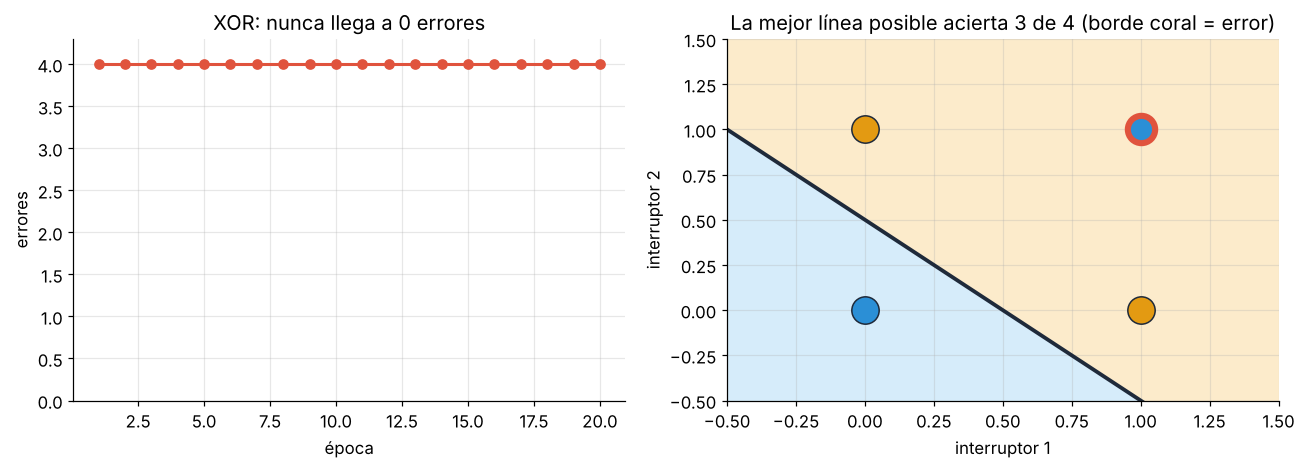

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].plot(range(1, len(hist_xor) + 1), hist_xor, "o-", color=CORAL, lw=2)
ax[0].set_ylim(0, 4.3); ax[0].set_xlabel("época"); ax[0].set_ylabel("errores")
ax[0].set_title("XOR: nunca llega a 0 errores")

# Even the best possible line (x1 + x2 = 0.5) gets one case wrong
w_best, b_best = np.array([1.0, 1.0]), -0.5
g1, g2 = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
ax[1].contourf(g1, g2, (w_best[0] * g1 + w_best[1] * g2 + b_best) >= 0, levels=[-.5, .5, 1.5], colors=["#D6ECFA", "#FCEBCB"])
pred = np.where(X_xor @ w_best + b_best >= 0, 1, -1)
for (a, b_), t, p in zip(X_xor, y_xor, pred):
    ax[1].scatter(a, b_, s=320, color=AMBAR if t == 1 else AZUL, edgecolor=CORAL if p != t else TINTA,
                  linewidth=4 if p != t else 1, zorder=3)
xs = np.linspace(-0.5, 1.5, 50)
ax[1].plot(xs, 0.5 - xs, color=TINTA, lw=2.5)
ax[1].set_xlim(-0.5, 1.5); ax[1].set_ylim(-0.5, 1.5); ax[1].set_xlabel("interruptor 1"); ax[1].set_ylabel("interruptor 2")
ax[1].set_title("La mejor línea posible acierta 3 de 4 (borde coral = error)")
plt.tight_layout(); plt.show()

**Qué deberías ver:** **4 errores en todas las épocas**: `[4, 4, 4, …]`. En cada época hace **4 correcciones** y la línea se mueve en cada una: w pasa por (0, 0) → (0, 1) → (1, 1) → (0, 0), con b = −1, 0, +1, 0… y **vuelve exactamente al punto de partida**. Se mueve todo el tiempo, pero da vueltas en círculo.
A la derecha, incluso la mejor línea posible deja un caso del lado equivocado: las dos luces encendidas (ámbar) están en esquinas opuestas y ninguna recta las junta sin llevarse una apagada.

En el negocio esto aparece cuando el efecto de una variable **depende de otra** (por ejemplo, el garante ayuda solo si la cuota es baja). Mañana lo resolvemos con **más de una neurona**.

### 💭 Para pensar

**1.** ¿Le faltan épocas? ¿Con 1 000 épocas lo lograría?

<details><summary>Ver respuesta</summary>

No. Los errores se repiten igual en todas las épocas y la línea vuelve al mismo lugar: más vueltas dan el mismo resultado.
</details>

**2.** ¿Entonces cuál es el problema de fondo?

<details><summary>Ver respuesta</summary>

Que **no existe una línea recta** que deje (0,1) y (1,0) de un lado y (0,0) y (1,1) del otro. Una sola neurona solo sabe trazar una línea.
</details>

**3.** ¿Cambiar η (el tamaño de la pizca) lo arreglaría?

<details><summary>Ver respuesta</summary>

No. Con cualquier η pasa lo mismo: el problema no es el tamaño del paso sino la **forma** de la frontera.
</details>

---
## 6 · Error y pérdida: ¿qué tan mal lo hicimos?
📽 Láminas 31–33

**Qué vas a hacer:** medir qué tan mal predice un modelo con **un solo número**, para precios (MSE) y para sí/no (BCE).

**La necesidad:** el perceptrón solo sabe "acerté / me equivoqué". Para aprender mejor necesitamos saber **cuánto** nos equivocamos, y resumirlo en un número que podamos hacer bajar.

> ### Tres palabras que no hay que mezclar
> | Palabra | Qué es | Cuántos números | Ejemplo (casas) |
> |---|---|---|---|
> | **error** | lo real menos lo predicho, **en un caso** | uno por caso | casa 3: 150 − 170 = **−20** |
> | **pérdida** | un **resumen de todos** los errores en un solo número; 0 es perfecto | **uno** para todo el grupo | MSE = **132.25** |
> | **gradiente** | hacia dónde mover cada peso para que la pérdida baje (sección 7) | uno por peso | — |
>
> La **pérdida** (en inglés *loss*) es una medida de qué tan mal vamos. **No es dinero perdido**: no son dólares.

**El nombre (para números): error cuadrático medio, MSE.**
$$\text{MSE} = \frac{1}{N}\sum_{i=1}^{N} (y_i - \hat y_i)^2$$
**Léelo así:** "para cada caso, resta lo real ($y$) menos lo predicho ($\hat y$, se lee *y gorro*), eleva al cuadrado y saca el promedio". Al cuadrado, los negativos no restan y los errores grandes pesan muchísimo. Ojo con las **unidades**: si los precios están en miles de USD, el MSE queda en *miles de USD al cuadrado*, por eso no se lee como "me equivoqué 132 mil dólares".

**El nombre (para sí/no): entropía cruzada binaria, BCE**, cuando el modelo da una probabilidad $\hat y$ (y aquí las etiquetas son 1 = pagó, 0 = no pagó):
$$\text{BCE} = -\big[\,y\log\hat y + (1-y)\log(1-\hat y)\,\big]$$
**Léelo así:** "menos el logaritmo de la probabilidad que el modelo le dio a lo que de verdad pasó". Si pagó ($y=1$) queda $-\log\hat y$; si no pagó ($y=0$) queda $-\log(1-\hat y)$. Como el **meteorólogo** que dijo "99 % sin lluvia" el día del aguacero: estar **seguro y equivocado** cuesta carísimo.

### Ejemplo: cuatro casas en Quito y un socio que sí pagó
**Qué hace este código:**
- `errors = real - pred` calcula el **error** de cada casa (cuatro números).
- `np.mean(errors**2)` eleva al cuadrado y promedia: la **pérdida** MSE (un número).
- El `for` calcula la BCE de un socio que **sí pagó** cuando el modelo le dio 99 %, 90 %, 50 %, 10 % y 1 %.

🔮 **Antes de ejecutar:** ¿qué casa crees que aporta más al MSE? ¿Y cuánto costará haber dicho 1 % a alguien que sí pagó: el doble que 50 %, o mucho más?

In [25]:
# MSE: predicted vs real house prices in Quito (thousands of USD)
real = np.array([120, 95, 150, 80])
pred = np.array([110, 100, 170, 82])
errors = real - pred                     # one error per house
print("Errores:", errors, "| al cuadrado:", errors**2, "| MSE =", np.mean(errors**2))

# BCE: the real answer is y = 1 ("sí pagó"). How much does each prediction cost?
for p in [0.99, 0.9, 0.5, 0.1, 0.01]:
    print(f"El modelo dijo {p:4.2f} -> pérdida = -log({p}) = {-np.log(p):.2f}")

Errores: [ 10  -5 -20  -2] | al cuadrado: [100  25 400   4] | MSE = 132.25
El modelo dijo 0.99 -> pérdida = -log(0.99) = 0.01
El modelo dijo 0.90 -> pérdida = -log(0.9) = 0.11
El modelo dijo 0.50 -> pérdida = -log(0.5) = 0.69
El modelo dijo 0.10 -> pérdida = -log(0.1) = 2.30
El modelo dijo 0.01 -> pérdida = -log(0.01) = 4.61


**Qué hace este código:** a la izquierda compara el error de cada casa con su cuadrado; a la derecha dibuja la curva $-\log(p)$ de la BCE.

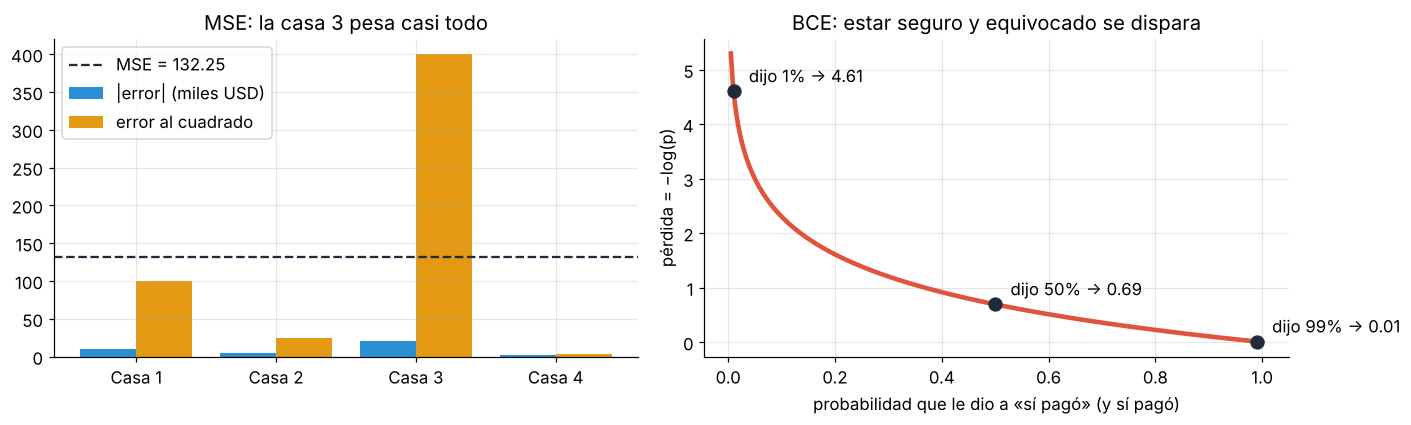

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
casas = ["Casa 1", "Casa 2", "Casa 3", "Casa 4"]
pos = np.arange(4)
ax[0].bar(pos - .2, np.abs(errors), .4, color=AZUL, label="|error| (miles USD)")
ax[0].bar(pos + .2, errors**2, .4, color=AMBAR, label="error al cuadrado")
ax[0].axhline(np.mean(errors**2), color=TINTA, ls="--", label=f"MSE = {np.mean(errors**2):.2f}")
ax[0].set_xticks(pos, casas); ax[0].legend(); ax[0].set_title("MSE: la casa 3 pesa casi todo")

ps = np.linspace(0.005, 1, 300)
ax[1].plot(ps, -np.log(ps), color=CORAL, lw=3)
for p in [0.99, 0.5, 0.01]:
    ax[1].scatter(p, -np.log(p), s=70, color=TINTA, zorder=3)
    ax[1].annotate(f"dijo {p:.0%} → {-np.log(p):.2f}", (p, -np.log(p)), textcoords="offset points", xytext=(10, 6))
ax[1].set_xlabel("probabilidad que le dio a «sí pagó» (y sí pagó)"); ax[1].set_ylabel("pérdida = −log(p)")
ax[1].set_title("BCE: estar seguro y equivocado se dispara")
plt.tight_layout(); plt.show()

**Qué deberías ver:** errores `[ 10  -5 -20  -2]`, al cuadrado `[100  25 400   4]`, **MSE = 132.25** (la casa 3 aporta 400 de los 529). En la BCE: 0.99 → **0.01**, 0.5 → **0.69** y 0.01 → **4.61**; la curva coral sube en picada cuando el modelo estaba seguro de lo contrario.

### Las dos pérdidas como funciones
**Qué hace este código:**
- `mse(real, pred)` empaqueta la cuenta de arriba para cualquier par de listas.
- `bce(y, p)` es la fórmula completa, para **un** caso con $y$ = 1 o 0. Fíjate que según $y$ se "apaga" una de las dos partes.
- Las tres líneas de `print` comprueban las funciones con números que ya conocemos.

🔮 **Antes de ejecutar:** el modelo dijo 90 % de pago. ¿Cuesta más si el socio pagó o si no pagó?

In [27]:
def mse(real, pred):
    return np.mean((np.asarray(real) - np.asarray(pred)) ** 2)      # average squared error

def bce(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))               # y = 1 or 0, p = predicted probability

print("comprobación MSE casas:", mse(real, pred))
print(f"BCE: dijo 0.9 y SÍ pagó (y = 1): {bce(1, 0.9):.3f}")
print(f"BCE: dijo 0.9 y NO pagó (y = 0): {bce(0, 0.9):.3f}")

comprobación MSE casas: 132.25
BCE: dijo 0.9 y SÍ pagó (y = 1): 0.105
BCE: dijo 0.9 y NO pagó (y = 0): 2.303


**Qué deberías ver:** `132.25`, **0.105** (pagó: acertó con bastante seguridad, cuesta poco) y **2.303** (no pagó: estaba seguro y se equivocó, cuesta 22 veces más).

### 💭 Para pensar

**1.** ¿Cuál es la diferencia entre **error** y **pérdida**?

<details><summary>Ver respuesta</summary>

El error es de **un caso** (real − predicho: hay uno por casa). La pérdida **resume todos** los errores en un solo número (el MSE de las cuatro casas).
</details>

**2.** Un compañero dice: «el MSE de 132.25 significa que perdimos 132 mil dólares». ¿Qué le respondes?

<details><summary>Ver respuesta</summary>

Que la pérdida no es dinero: es una medida de qué tan mal vamos. Además, el MSE está en *miles de USD al cuadrado*; el error típico se parece más a $\sqrt{132.25} \approx 11.5$ mil USD.
</details>

**3.** ¿Por qué la BCE castiga tanto decir 1 % a alguien que sí pagó?

<details><summary>Ver respuesta</summary>

Porque $-\log(0.01) = 4.61$: el logaritmo se dispara cerca de 0. Estar **seguro y equivocado** es lo peor que puede hacer un modelo de probabilidades.
</details>

---
## 7 · Derivada y descenso de gradiente: bajar el Cotopaxi con neblina
📽 Láminas 34–36

**Qué vas a hacer:** bajar por una curva de pérdida dando pasos, como lo hace cualquier red al entrenar.

**La necesidad:** ya sabemos medir qué tan mal vamos (la pérdida). Ahora necesitamos saber **hacia dónde mover cada peso** para que esa pérdida baje.

**La idea:** estás en la ladera del Cotopaxi con neblina y quieres llegar a la laguna de abajo. No ves el camino, pero con el pie sientes hacia dónde baja el terreno (la **pendiente**) y das un paso hacia allá. Vuelves a tantear y das otro.

**El nombre:** la **derivada** de la pérdida respecto a un peso dice **cuánto cambia la pérdida si giras un poquito ese peso**, como una perilla:
- derivada **positiva** → si subes el peso, la pérdida sube → hay que **bajarlo**;
- derivada **negativa** → si subes el peso, la pérdida baja → hay que **subirlo**;
- derivada **cero** → estás en el fondo (o en un llano).

Cuando hay muchos pesos, cada uno tiene su derivada. La **lista de todas las derivadas** se llama **gradiente**. Y **descenso de gradiente** es dar un paso con todos los pesos en contra de su derivada.

| En la montaña | En el entrenamiento |
|---|---|
| la altura | la pérdida |
| dónde estás parado | los pesos $w$ |
| la inclinación bajo tus pies | la derivada (con muchos pesos: el gradiente) |
| el largo de tu paso | η, la tasa de aprendizaje |

$$w_{\text{nuevo}} = w - \eta \cdot \text{derivada}$$

**Léelo así:** "el peso nuevo es el peso actual **menos** η por la derivada". Se **resta** porque la derivada apunta cuesta **arriba**.

### Ejemplo: una sola perilla, a mano
Un peso vale **2**, la derivada de la pérdida en ese punto es **+4** y η = **0.1**.

**Qué hace este código:** aplica la fórmula una vez con derivada +4 y otra vez con derivada −4.

🔮 **Antes de ejecutar:** con derivada +4, ¿el peso sube o baja? ¿Cuánto?

In [28]:
peso, eta = 2.0, 0.1
for derivada in [+4.0, -4.0]:
    nuevo = peso - eta * derivada            # one gradient-descent step
    print(f"peso {peso} · derivada {derivada:+.0f} · η {eta}  →  {peso} - {eta}·({derivada:+.0f}) = {nuevo:.1f}")

peso 2.0 · derivada +4 · η 0.1  →  2.0 - 0.1·(+4) = 1.6
peso 2.0 · derivada -4 · η 0.1  →  2.0 - 0.1·(-4) = 2.4


**Qué deberías ver:** con derivada +4 el peso **baja** a **1.6** (2 − 0.4); con derivada −4 **sube** a **2.4** (2 + 0.4). El signo de la derivada decide la dirección; η decide el largo del paso.

### Ejemplo: bajar una montaña completa
Pérdida $L(w) = (w - 3)^2$: su fondo está en $w = 3$. Su derivada es $2(w-3)$. Empezamos en $w = 0$ con $\eta = 0.1$.

**Qué hace este código:**
- `L` es la pérdida y `slope` su derivada (pendiente).
- El ciclo `for` da 10 pasos; en cada uno imprime dónde está, la pendiente y la pérdida, y luego **baja**: `w = w - eta * slope(w)`.
- `path` guarda cada posición para dibujar el camino.

🔮 **Antes de ejecutar:** en $w = 0$ la derivada es $2(0 - 3) = -6$. ¿El primer paso lleva $w$ a la izquierda o a la derecha? ¿Hasta dónde?

In [29]:
L = lambda w: (w - 3) ** 2          # loss: a valley with its bottom at w = 3
slope = lambda w: 2 * (w - 3)       # its slope (derivative)

w, eta, path = 0.0, 0.1, [0.0]
print(" paso |    w    | pendiente | pérdida")
for step_i in range(10):
    print(f"  {step_i:2d}  | {w:7.3f} | {slope(w):9.3f} | {L(w):7.3f}")
    w = w - eta * slope(w)           # one step downhill
    path.append(w)

 paso |    w    | pendiente | pérdida
   0  |   0.000 |    -6.000 |   9.000
   1  |   0.600 |    -4.800 |   5.760
   2  |   1.080 |    -3.840 |   3.686
   3  |   1.464 |    -3.072 |   2.359
   4  |   1.771 |    -2.458 |   1.510
   5  |   2.017 |    -1.966 |   0.966
   6  |   2.214 |    -1.573 |   0.618
   7  |   2.371 |    -1.258 |   0.396
   8  |   2.497 |    -1.007 |   0.253
   9  |   2.597 |    -0.805 |   0.162


**Qué hace este código:** dibuja la curva de pérdida y, encima, los pasos que acabamos de dar.

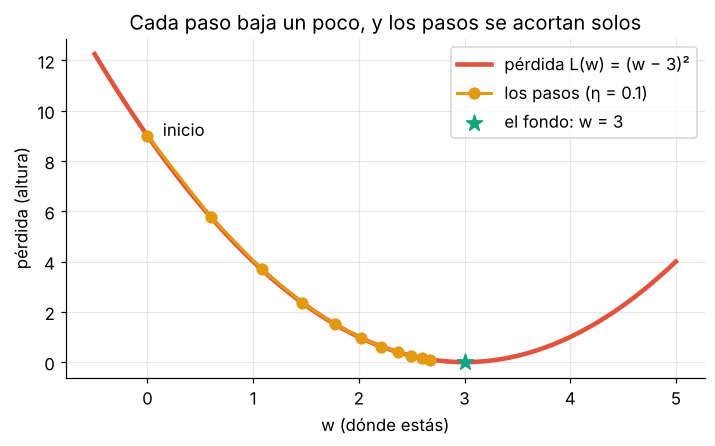

In [30]:
ws = np.linspace(-0.5, 5, 200)
plt.figure(figsize=(7.5, 4))
plt.plot(ws, L(ws), lw=3, color=CORAL, label="pérdida L(w) = (w − 3)²")
plt.plot(path, [L(p) for p in path], "o-", color=AMBAR, ms=7, lw=2, label="los pasos (η = 0.1)")
plt.annotate("inicio", (path[0], L(path[0])), textcoords="offset points", xytext=(10, 0))
plt.scatter([3], [0], s=120, marker="*", color=MENTA, zorder=3, label="el fondo: w = 3")
plt.xlabel("w (dónde estás)"); plt.ylabel("pérdida (altura)"); plt.legend()
plt.title("Cada paso baja un poco, y los pasos se acortan solos"); plt.show()

**Qué deberías ver:** w = 0 → 0.6 → 1.08 → 1.464 → 1.771 … acercándose a **3**, y la pérdida bajando de 9 hacia 0. Los pasos se acortan solos: cerca del fondo la pendiente es menor.

### Ejemplo: otra montaña, $L(w) = (w + 2)^2$
El fondo está donde $w + 2 = 0$, o sea en $w = -2$. Su derivada es $2(w + 2)$.

**Qué hace este código:** el mismo ciclo, ahora con 50 pasos y empezando en `w_inicio = 5`. Imprime solo algunos pasos para no llenar la pantalla.

🔮 **Antes de ejecutar:** empezamos a la **derecha** del fondo. ¿La primera derivada es positiva o negativa? ¿Hacia dónde se moverá $w$?

In [31]:
w_inicio = 5.0                      # starting point   (🧪 try -10)
eta = 0.1
w = w_inicio
for paso in range(1, 51):
    w = w - eta * 2 * (w + 2)       # derivative of (w + 2)^2 is 2 (w + 2)
    if paso in (1, 2, 3, 10, 25, 50):
        print(f"paso {paso:2d}: w = {w:8.4f}")
w_final = w
print(f"Fondo de la montaña: w = -2  ·  llegamos a w = {w_final:.4f}")

paso  1: w =   3.6000
paso  2: w =   2.4800
paso  3: w =   1.5840
paso 10: w =  -1.2484
paso 25: w =  -1.9736
paso 50: w =  -1.9999
Fondo de la montaña: w = -2  ·  llegamos a w = -1.9999


**Qué deberías ver:** w = 3.6 → 2.48 → 1.584 … y al paso 50, **w ≈ −1.9999**: llegó al fondo, −2.

🧪 **Experimenta:** cambia `w_inicio = 5.0` por `-10` y ejecuta. Ahora empiezas a la **izquierda** del fondo: la derivada es negativa y $w$ **sube** hasta −2. El método no necesita saber de qué lado estás: la derivada se lo dice.

### 💭 Para pensar

**1.** Un peso vale 2, su derivada es +4 y η = 0.1. ¿Cuál es el peso nuevo? ¿Y si la derivada fuera −4?

<details><summary>Ver respuesta</summary>

2 − 0.1·4 = **1.6**; con −4: 2 + 0.4 = **2.4**.
</details>

**2.** ¿Qué es el gradiente?

<details><summary>Ver respuesta</summary>

La **lista de las derivadas** de la pérdida respecto a cada peso: una por peso. Dice hacia dónde mover cada perilla.
</details>

**3.** ¿Por qué los pasos se vuelven más cortos cerca del fondo, si η no cambió?

<details><summary>Ver respuesta</summary>

Porque el paso es η × derivada, y cerca del fondo la derivada se acerca a 0: el terreno es casi plano.
</details>

---
## 8 · El tamaño del paso η importa
📽 Lámina 37

**Qué vas a hacer:** bajar la misma montaña con distintos tamaños de paso y comparar.

**La idea:** como **la ducha con agua caliente**: si giras la llave poquito a poco, tardas pero llegas a la temperatura justa; si la abres de golpe te quemas, la cierras de golpe te congelas… y nunca llegas.

**El nombre:** η (se lee *eta*) es la **tasa de aprendizaje**. Con η muy pequeño tardas una eternidad; con η muy grande te pasas del fondo y rebotas cada vez más lejos: eso se llama **divergir**.

### Ejemplo: misma montaña, tres pasos distintos
**Qué hace este código:**
- `descenso(eta, pasos=30, w=0.0)` empaqueta el descenso de la sección 7 sobre $L(w) = (w-3)^2$ y devuelve dónde terminó $w$.
- El `for` lo prueba con η = 0.02, 0.4 y 1.02.

🔮 **Antes de ejecutar:** ¿cuál de los tres crees que llega a 3? ¿Alguno puede terminar **lejos** de donde empezó?

In [32]:
def descenso(eta, pasos=30, w=0.0):
    # gradient descent on L(w) = (w - 3)^2; returns the final w
    for _ in range(pasos):
        w = w - eta * slope(w)
    return w

for eta in [0.02, 0.4, 1.02]:
    print(f"η = {eta:4}: después de 30 pasos w = {descenso(eta):10.3f}  (el fondo está en 3)")

η = 0.02: después de 30 pasos w =      2.118  (el fondo está en 3)
η =  0.4: después de 30 pasos w =      3.000  (el fondo está en 3)
η = 1.02: después de 30 pasos w =     -6.730  (el fondo está en 3)


**Qué hace este código:** dibuja 12 pasos con cada η sobre la misma curva.

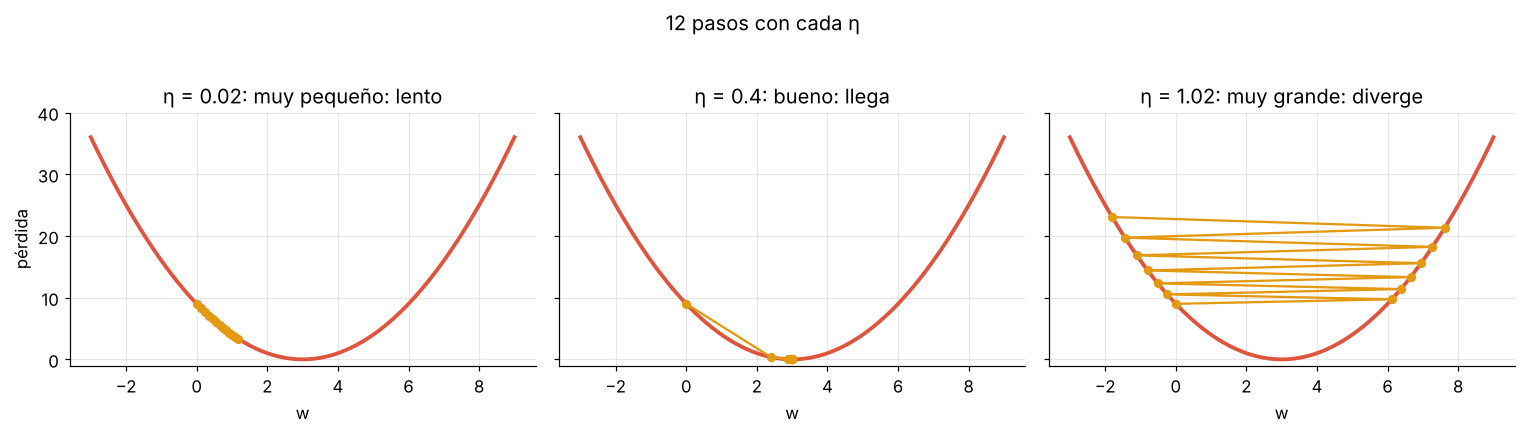

In [33]:
ws_wide = np.linspace(-3, 9, 300)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, eta, title in zip(ax, [0.02, 0.4, 1.02], ["muy pequeño: lento", "bueno: llega", "muy grande: diverge"]):
    w, path = 0.0, [0.0]
    for _ in range(12):
        w = w - eta * slope(w); path.append(w)
    a.plot(ws_wide, L(ws_wide), lw=2.5, color=CORAL)
    a.plot(path, [L(p) for p in path], "o-", color=AMBAR, ms=5)
    a.set_ylim(-1, 40); a.set_title(f"η = {eta}: {title}"); a.set_xlabel("w")
ax[0].set_ylabel("pérdida")
plt.suptitle("12 pasos con cada η", y=1.03); plt.tight_layout(); plt.show()

**Qué deberías ver:** con η = 0.02, w = **2.118** (apenas avanza); con η = 0.4, w = **3.000** (llega); con η = 1.02, w = **−6.730**: **rebota de lado a lado, cada vez más lejos** y la pérdida crece en vez de bajar (diverge). En Keras este número se llama `learning_rate`: si la pérdida sube o aparece `nan`, es lo primero que se revisa.

### ¿Cuáles convergen?
**Qué hace este código:** prueba cuatro η y decide solo si **se acerca** al fondo (converge) comparando la distancia final a 3 con la distancia inicial (3).

🔮 **Antes de ejecutar:** η = 0.9 es grande. ¿Converge o diverge? ¿Y 1.1?

In [34]:
for eta in [0.05, 0.5, 0.9, 1.1]:
    w_fin = descenso(eta)
    converge = abs(w_fin - 3) < 3                 # closer to the bottom than where we started (w = 0)
    print(f"η = {eta:4}: w final = {w_fin:12.3f}  →  {'converge' if converge else 'DIVERGE'}")

η = 0.05: w final =        2.873  →  converge
η =  0.5: w final =        3.000  →  converge
η =  0.9: w final =        2.996  →  converge
η =  1.1: w final =     -709.129  →  DIVERGE


**Qué deberías ver:** η = 0.05 → 2.873 (converge, lento); 0.5 → 3.000 (converge en **un** paso); 0.9 → 2.996 (converge **rebotando**); 1.1 → **−709.129 (diverge)**. Para esta montaña el límite está en η = 1: por debajo se acerca, por encima se aleja.

🧪 **Experimenta:** ¿qué η llega a menos de 0.01 del fondo en solo **10 pasos**? Cambia `mi_eta` y ejecuta.

In [35]:
mi_eta = 0.5                                      # step size   (🧪 try 0.1, 0.3, 0.9 or 1.1)
w10 = descenso(mi_eta, pasos=10)
print(f"Con η = {mi_eta}: después de 10 pasos w = {w10:.4f}  (distancia al fondo: {abs(w10 - 3):.4f})")

Con η = 0.5: después de 10 pasos w = 3.0000  (distancia al fondo: 0.0000)


**Qué deberías ver (con 0.5):** `w = 3.0000`, distancia 0. Con 0.3 llegas a 2.9997 (también sirve); con 0.1 a 2.6779 (te falta); con 0.9 también a 2.6779, pero rebotando; y con 1.1 a −15.5752 (te alejas). Cualquier η entre ~0.22 y ~0.78 llega en 10 pasos.

### 💭 Para pensar

**1.** ¿Qué significa que el descenso **diverja**?

<details><summary>Ver respuesta</summary>

Que cada paso te deja **más lejos** del fondo que el anterior: la pérdida sube en vez de bajar.
</details>

**2.** Entrenas una red y la pérdida sube o sale `nan`. ¿Qué revisas primero?

<details><summary>Ver respuesta</summary>

La tasa de aprendizaje (`learning_rate`): probablemente es demasiado grande. Prueba dividirla entre 10.
</details>

**3.** Si η muy grande es malo, ¿por qué no usar siempre uno pequeñísimo?

<details><summary>Ver respuesta</summary>

Porque llegarías, pero muy lento: con η = 0.02, en 30 pasos todavía estás en 2.12. El arte es un η que llegue sin rebotar.
</details>

---
## Resumen en 5 líneas
1. Una neurona **multiplica, suma y decide**: $z = \mathbf{w}\cdot\mathbf{x} + b$, como tu nota final (pesos = porcentajes, sesgo = la exigencia con el signo cambiado).
2. La **activación** convierte el puntaje en la salida: escalón (sí/no), sigmoide (probabilidad estimada) o ReLU.
3. El perceptrón aprende **corrigiendo sus errores** con una pizca (η), pero una sola neurona solo traza **una línea**: no puede con XOR.
4. El **error** es de un caso; la **pérdida** resume todos en un número: MSE para números, BCE para sí/no.
5. La **derivada** dice hacia dónde mover cada peso; el **descenso de gradiente** da pasos en contra de ella, y el tamaño del paso η decide si llegas, tardas o diverges.

**Mañana:** juntamos neuronas en capas, vemos cómo aprende una red completa (retropropagación) y pasamos a Keras con el **NB02**.

---
## 🏁 Para comprobar que entendiste
Responde cada pregunta **antes** de abrir la respuesta. Si fallas alguna, vuelve a la sección indicada.

**Un ejemplo para mirar primero.** `GRUPO6` (ya cargado) tiene las notas de 6 estudiantes (S1, S2, S3, Final). **Qué hace este código:** aplica la neurona de la sección 1 a las 6 filas a la vez (`GRUPO6 @ w_nota`), resta la exigencia de 70 y cuenta cuántos tienen $z \ge 0$.

In [36]:
print(GRUPO6)
notas6 = GRUPO6 @ w_nota                     # one weighted grade per row
z6 = notas6 - 70                             # the neuron's score with b = -70
print("Notas:", np.round(notas6, 1))
print("z    :", np.round(z6, 1))
print("Aprueban:", int((z6 >= 0).sum()), "de", len(z6))

[[85 90 80 75]
 [70 60 65 80]
 [55 75 70 90]
 [90 95 85 40]
 [65 60 55 70]
 [72 68 74 66]]
Notas: [83.  68.  71.3 80.  62.  70.3]
z    : [13.  -2.   1.3 10.  -8.   0.3]
Aprueban: 4 de 6


**Qué deberías ver:** notas `[83.  68.  71.3 80.  62.  70.3]` y **4 de 6** aprueban.

### 💭 Preguntas

**1.** En `GRUPO6`, el cuarto estudiante sacó 90, 95 y 85 en las semanas pero 40 en el proyecto. ¿Aprueba? ¿Por qué el 40 no lo hunde?

<details><summary>Ver respuesta</summary>

Sí, con 80. El proyecto pesa solo 20 %: aporta 8 puntos; las semanas aportan 72. (Sección 1)
</details>

**2.** El sexto estudiante tiene $z = +0.3$. Si la exigencia subiera a 71, ¿qué pasaría y qué número de la neurona cambiaría?

<details><summary>Ver respuesta</summary>

Pasaría a $z = -0.7$ y no aprobaría. Solo cambia el **sesgo**, de −70 a −71. (Sección 1)
</details>

**3.** Un dato escalado vale −1. ¿Qué significa?

<details><summary>Ver respuesta</summary>

Que está **por debajo del promedio** (por ejemplo, ingreso 800 cuando el promedio es 1 000 y la variación típica 200). (Sección 1)
</details>

**4.** Para $z = 2.81$ la sigmoide da 0.943. Explícalo en una frase sin la palabra «garantía».

<details><summary>Ver respuesta</summary>

El modelo **estima** que de cada 100 socios parecidos pagarían unos 94. (Sección 2)
</details>

**5.** En la regla del perceptrón, ¿qué pasa con los pesos si $y = -1$ y la neurona se equivocó?

<details><summary>Ver respuesta</summary>

Se les **resta** el dato (por η): $\mathbf{w} - \eta\mathbf{x}$, y el sesgo baja η. (Sección 3)
</details>

**6.** ¿Por qué el perceptrón aprende AND pero no XOR?

<details><summary>Ver respuesta</summary>

AND se separa con una línea recta; XOR no: sus dos casos +1 están en esquinas opuestas. Una neurona solo traza una línea. (Secciones 4–5)
</details>

**7.** Real 150, predicho 170. ¿Cuál es el error de ese caso? ¿Y su aporte a la suma del MSE?

<details><summary>Ver respuesta</summary>

Error = 150 − 170 = **−20**; al cuadrado aporta **400**. (Sección 6)
</details>

**8.** ¿Error, pérdida o gradiente? «Un solo número que resume qué tan mal predice el modelo con todos los datos.»

<details><summary>Ver respuesta</summary>

**Pérdida.** El error es de un caso y el gradiente es la lista de derivadas. (Sección 6)
</details>

**9.** Un peso vale 2, su derivada es −4 y η = 0.1. ¿Peso nuevo?

<details><summary>Ver respuesta</summary>

2 − 0.1·(−4) = **2.4**: la derivada negativa hace **subir** el peso. (Sección 7)
</details>

**10.** La pérdida de tu entrenamiento sube en cada época. ¿Qué número cambias primero y hacia dónde?

<details><summary>Ver respuesta</summary>

La tasa de aprendizaje η: la **bajas** (por ejemplo, la divides entre 10). (Sección 8)
</details>

---
### 🧪 Experimento 1 (opcional): tu propio comité de crédito
📽 Lámina 40

Seis socios de la cooperativa, con dos datos escalados: **ingreso** y **atrasos previos**. Tres pagaron (ámbar) y tres no (azul).

| Socio | Ingreso | Atrasos | ¿Pagó? |
|---|---|---|---|
| Ana | 0.9 | −0.8 | sí |
| Byron | 0.4 | −0.2 | sí |
| Carla | 0.8 | 0.3 | sí |
| Diego | −0.5 | 0.6 | no |
| Elena | 0.1 | 0.5 | no |
| Fabián | −0.3 | −0.1 | no |

**Qué hace este código:**
- `w_comite = [w_ingreso, w_atrasos]` y `b_comite` son los pesos y el sesgo de **tu** comité (ya vienen unos que funcionan).
- `dibujar_comite(...)` dibuja a los seis socios y la frontera $z = 0$ de tu neurona.
- El `for` calcula $z$ para cada socio, decide y marca si acertó (`ok`) o se equivocó (`ERROR`).

**Tu misión:** cambia **un** número a la vez, ejecuta y mira qué le pasa a la línea y al conteo. Por ejemplo:
- `b_comite = -0.2` → prueba `-0.5`: el comité se vuelve **más exigente**. ¿A quién deja de aprobar?
- `w_comite = [1.0, -1.5]` → prueba `[1.0, 1.5]`: los atrasos **sumarían** a favor. ¿Cuántos aciertos quedan?

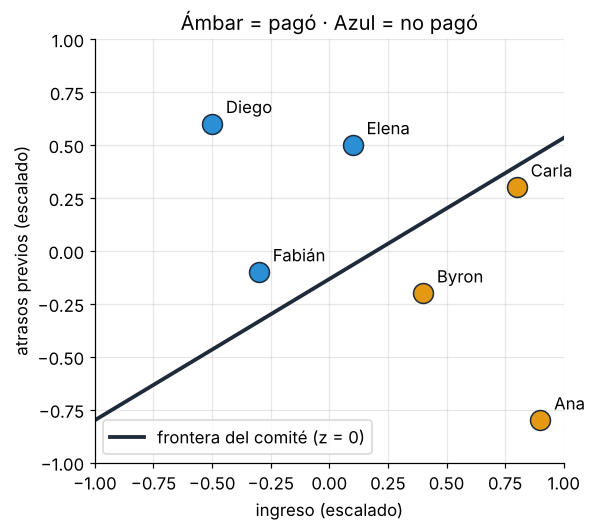

  Ana     z = +1.90 → aprueba   ok
  Byron   z = +0.50 → aprueba   ok
  Carla   z = +0.15 → aprueba   ok
  Diego   z = -1.60 → rechaza   ok
  Elena   z = -0.85 → rechaza   ok
  Fabián  z = -0.35 → rechaza   ok
Aciertos: 6 de 6


In [37]:
w_comite = [1.0, -1.5]    # [income weight, delays weight]   (🧪 try [1.0, 1.5] or [0.3, -1.5])
b_comite = -0.2           # how demanding the committee is    (🧪 try -0.5 or +0.5)

dibujar_comite(w_comite, b_comite)
z_socios = SOCIOS @ np.array(w_comite) + b_comite
aciertos = 0
for nombre, z_s, y_s in zip(NOMBRES, z_socios, PAGO):
    decide = 1 if z_s >= 0 else -1
    aciertos += int(decide == y_s)
    print(f"  {nombre:7s} z = {z_s:+.2f} → {'aprueba' if decide == 1 else 'rechaza'}   {'ok' if decide == y_s else 'ERROR'}")
print(f"Aciertos: {aciertos} de 6")

**Qué deberías ver (con los valores originales):** la línea deja a Ana, Byron y Carla del lado ámbar; $z$ = +1.90, +0.50, **+0.15**, −1.60, −0.85, −0.35 y **6 de 6** aciertos. Carla (+0.15) está muy cerca de la frontera.

**Bonus:** ¿qué pesos encontraría el perceptrón solo? **Qué hace este código:** entrena `train_perceptron` con los seis socios y dibuja su frontera para compararla con la tuya.

Errores por época: [2, 0] | pesos aprendidos: [ 1.4 -1.4] | sesgo: 0.0


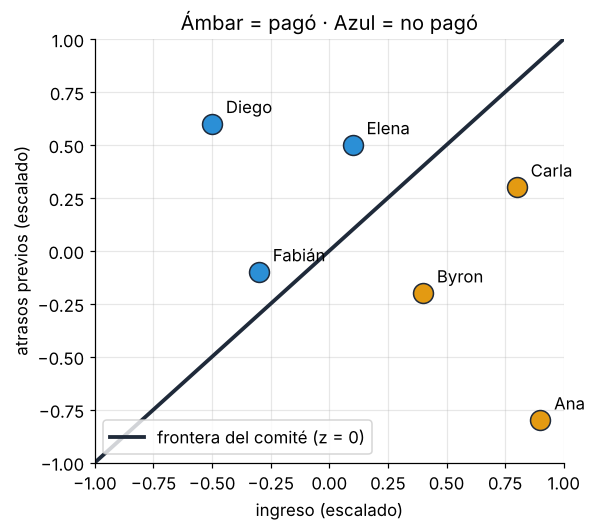

In [38]:
w_aprendido, b_aprendido, hist_comite = train_perceptron(SOCIOS, PAGO)
print("Errores por época:", hist_comite, "| pesos aprendidos:", w_aprendido, "| sesgo:", b_aprendido)
dibujar_comite(w_aprendido, b_aprendido)

**Qué deberías ver:** errores por época `[2, 0]`, pesos **(1.4, −1.4)** y sesgo 0: también 6 de 6, con otra línea. Los dos comités tienen el peso de los atrasos **negativo**.

### 💭 Para pensar

**1.** ¿Qué signo debería tener el peso de los atrasos? ¿Por qué?

<details><summary>Ver respuesta</summary>

Negativo: más atrasos que el promedio deben **restar** puntaje. Con +1.5 el comité premiaría los atrasos y se equivoca con varios socios.
</details>

**2.** Carla está cerca de la frontera. ¿Qué le pasa si haces al comité más exigente (`b_comite = -0.5`)?

<details><summary>Ver respuesta</summary>

Su $z$ pasa de +0.15 a −0.15: queda **rechazada** aunque pagó. Un comité más exigente se equivoca con los casos límite.
</details>

**3.** Tu comité y el perceptrón encontraron líneas distintas y ambas aciertan 6 de 6. ¿Cuál es «la correcta»?

<details><summary>Ver respuesta</summary>

Las dos separan bien **estos** seis socios. Para saber cuál es mejor necesitaríamos **socios nuevos** que ninguna haya visto: eso es la validación, que veremos con Keras.
</details>

---
**¿Te quedó alguna duda?** Repasa las slides interactivas y la guía de estudio desde la página del curso. Mañana seguimos con el **NB02 · Tu primera red**.